In [44]:
import os
import sys
root = os.path.abspath("..")
sys.path.append(root)

import io
import shutil
import pickle
import torch
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from datetime import datetime
from collections import defaultdict

from config import Config
from simulation.impl.trajectory_with_metrics import TrajectoryWithMetrics

if shutil.which("latex"):
    plt.style.use(["science", "ieee"])
else:
    plt.style.use(["science", "ieee", "no-latex"])

config = Config()
figures_dir = os.path.join(config.resource_dir, "figures")
os.makedirs(figures_dir, exist_ok=True)

In [45]:
class CPU_Unpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if module == 'torch.storage' and name == '_load_from_bytes':
            return lambda b: torch.load(io.BytesIO(b), map_location='cpu')
        return super().find_class(module, name)

In [ ]:
TRAJECTORY_DIR = "path/to/trajectories"
EXPERIMENT_DIR = os.path.abspath("../experiments")
CLIENT_CPU_BASE = 200.0


def get_policy_label(experiment):
    policy = experiment["server_policy"]
    scale = experiment.get("server_policy_smart_priority_scale", 1.0)
    if policy == "smart" and float(scale) > 1.0:
        return "smartx"
    return policy


def load_records():
    datetimes = {}
    paths = {}
    devices = {}

    for filename in os.listdir(TRAJECTORY_DIR):
        if not filename.startswith("trajectory_exp_simulation"):
            continue
        match = re.findall(r"trajectory_exp_simulation_(.+)_(.+)_(.+)\.pkl", filename)
        if not match:
            continue
        device, idx, date_str = match[0]
        idx = int(idx)
        date_str = datetime.fromisoformat(date_str)
        if idx not in datetimes or date_str > datetimes[idx]:
            devices[idx] = device
            paths[idx] = os.path.join(TRAJECTORY_DIR, filename)
            datetimes[idx] = date_str

    records = []
    for idx, path in paths.items():
        exp_path = os.path.join(EXPERIMENT_DIR, f"exp_simulation_{devices[idx]}_{idx}.json")
        if not os.path.exists(exp_path):
            continue
        with open(exp_path) as f:
            experiment = json.load(f)
        records.append((idx, path, experiment))

    print(f"Loaded {len(records)} records")
    return records


records = load_records()

Loaded 160 records


In [47]:
POLICIES = ["centralized", "default", "smart"]  #, "smartx"]
POLICY_LABELS = ["Centralized", "Uniform", "Affinity"]  #, "SmartX"]


def fmt_clients(n):
    if n >= 1000:
        return f"{n // 1000}k"
    return str(n)

In [48]:
# key: (policy, server_mult, n_clients, client_mult, task_idx) -> list of (p99, cum_total_latency, cum_mean_latency)
px_data = defaultdict(list)
n_tasks = None

for idx, path, exp in records:
    trajectory: TrajectoryWithMetrics = CPU_Unpickler(open(path, "rb")).load()

    if n_tasks is None:
        n_tasks = len(trajectory.p99_latency)

    policy     = get_policy_label(exp)
    server_cpu = exp["available_resource_params"]["server"]["cpu"]["max"]
    client_cpu = exp["available_resource_params"]["client"]["cpu"]["max"]
    n_clients  = exp["n_clients"]

    server_mult = int(round(server_cpu / CLIENT_CPU_BASE))
    client_mult = int(round(client_cpu / CLIENT_CPU_BASE))

    for t in range(n_tasks):
        p99       = trajectory.p99_latency[t][-1]       if trajectory.p99_latency[t]       else np.nan
        cum_total = trajectory.cum_total_latency[t][-1] if trajectory.cum_total_latency[t] else np.nan
        cum_mean  = trajectory.cum_mean_latency[t][-1]  if trajectory.cum_mean_latency[t]  else np.nan
        px_data[(policy, server_mult, n_clients, client_mult, t)].append((p99, cum_total, cum_mean))

TASK_LABELS = [f"Query {t + 1}" for t in range(n_tasks)]
print(f"n_tasks: {n_tasks}, unique keys: {len(px_data)}")

n_tasks: 4, unique keys: 640


In [49]:
server_mults = sorted({k[1] for k in px_data})
x_configs    = sorted({(k[2], k[3]) for k in px_data})
x_labels     = [f"{fmt_clients(n)}\n{m}x" for n, m in x_configs]
x_pos        = list(range(len(x_configs)))

Figure 1 — server 10x  →  px_latencies_p99_server_10x.pdf


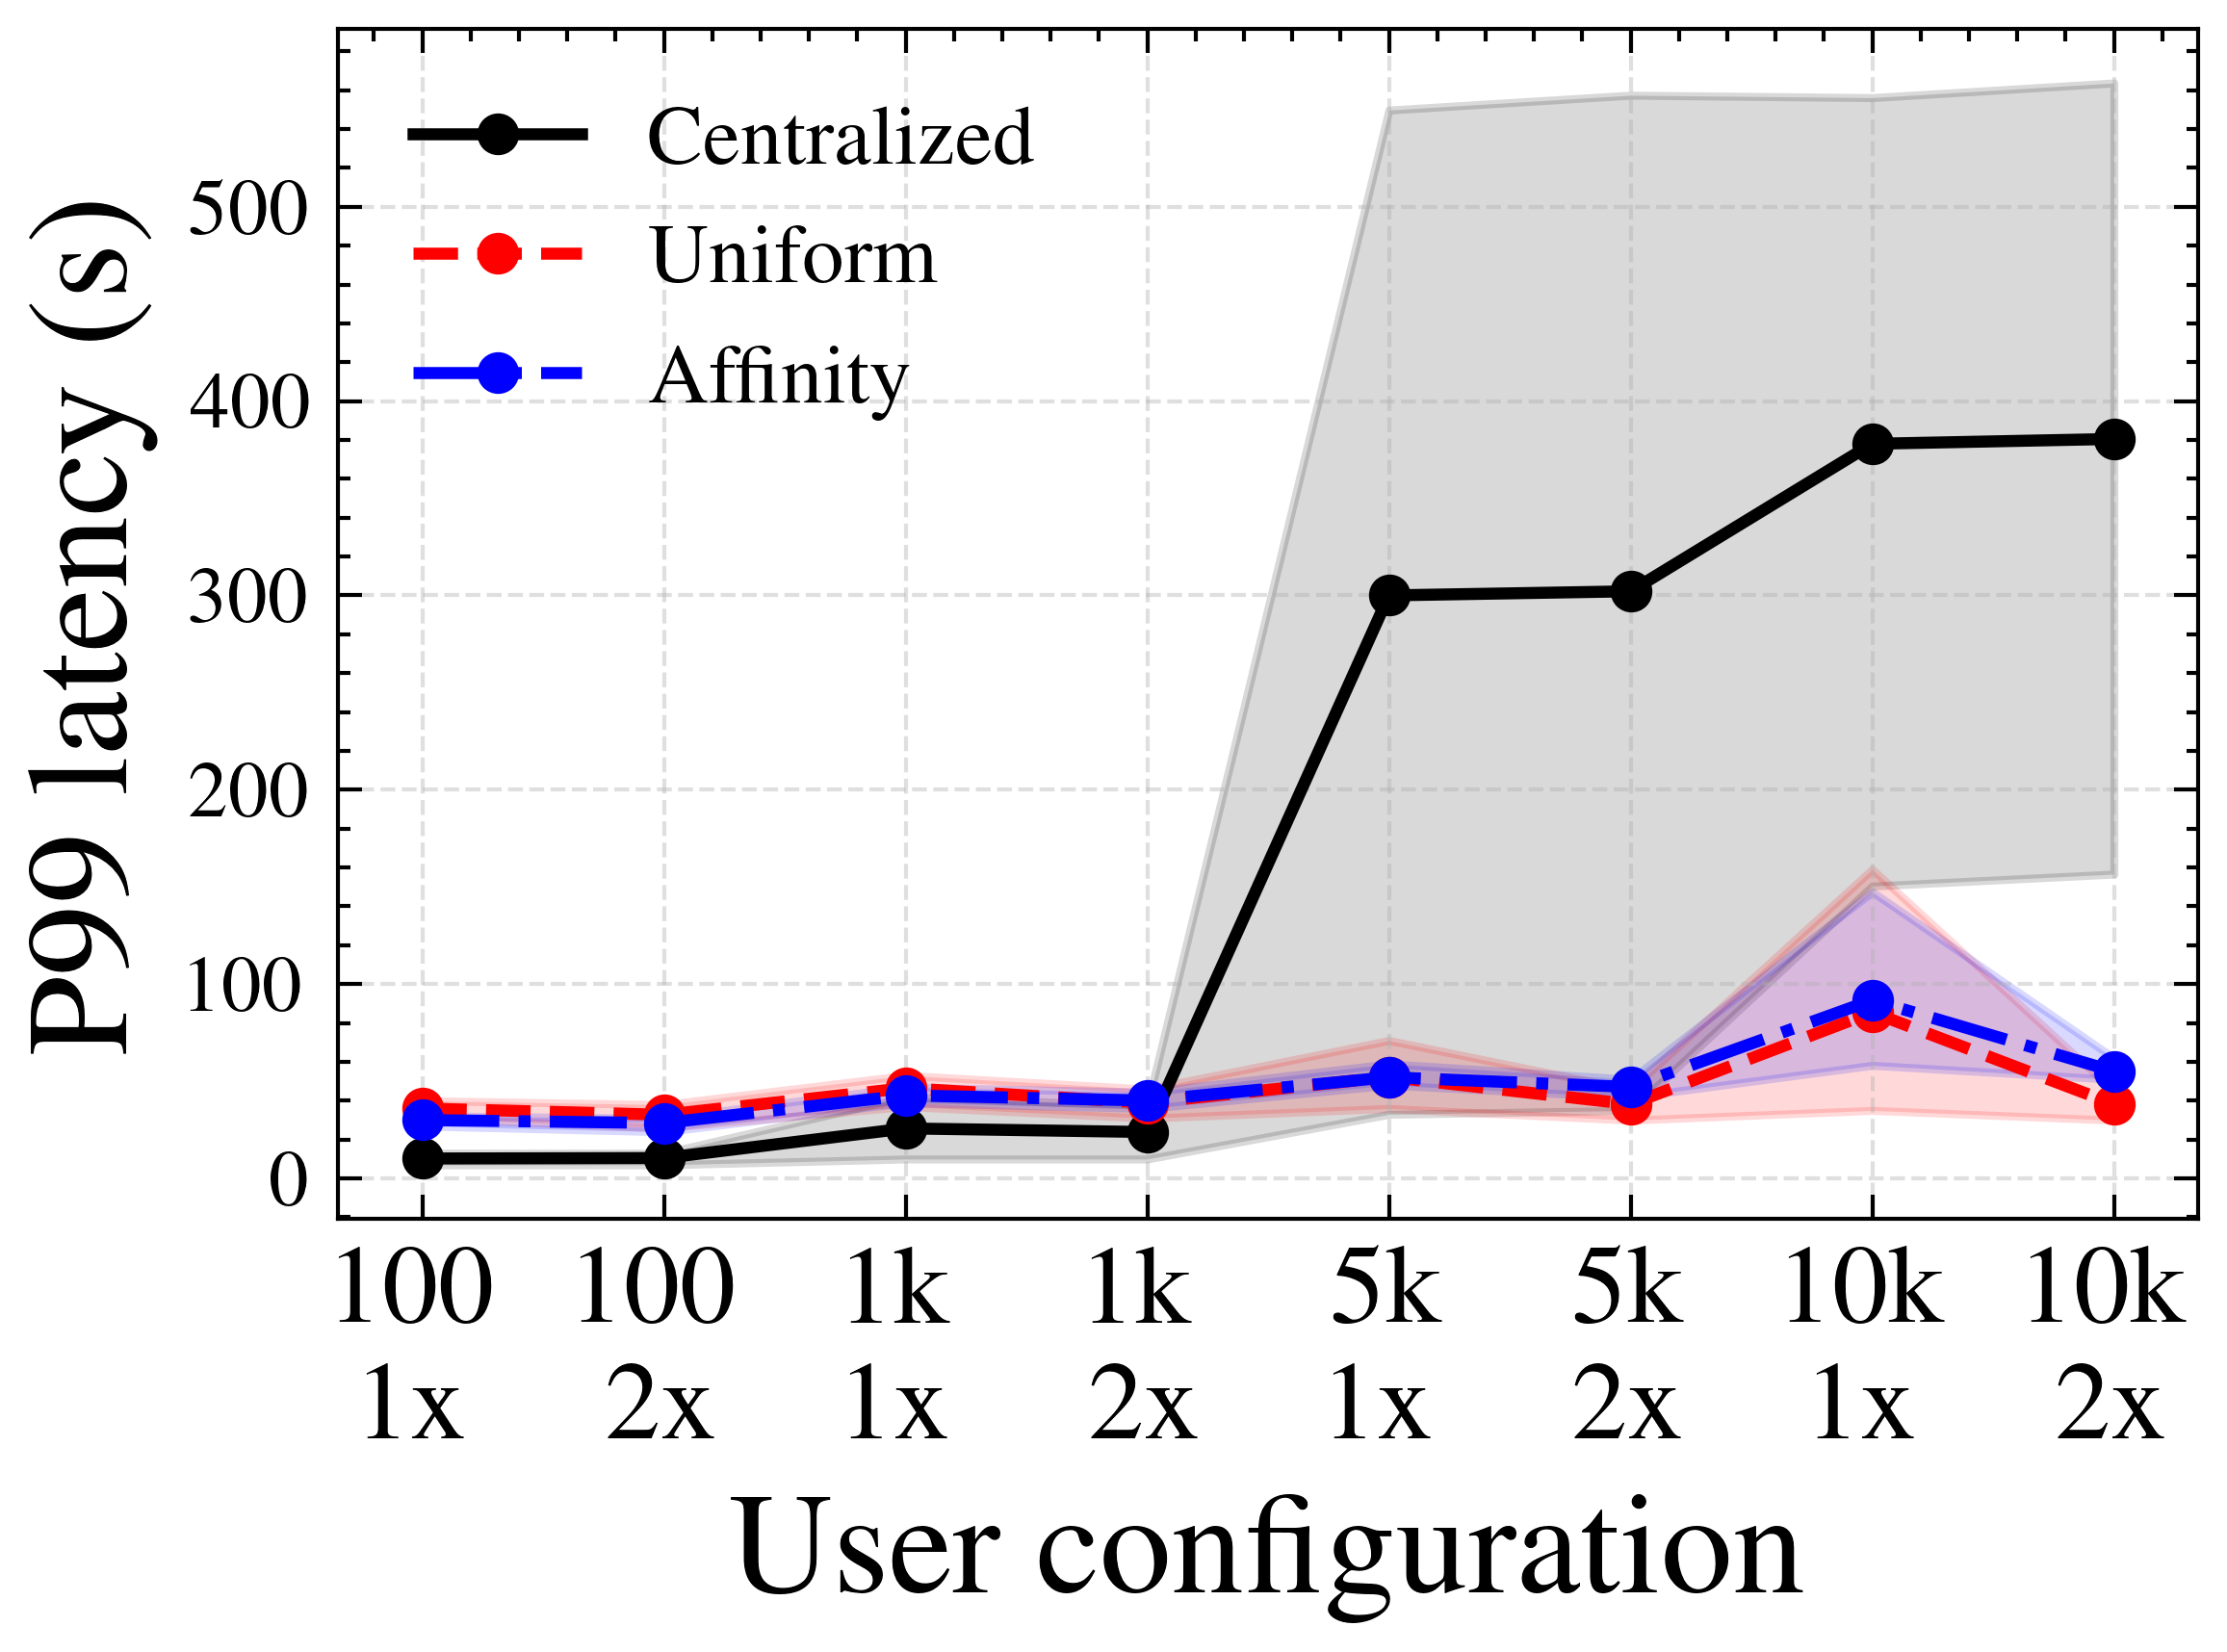

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_9245/3042910666.py:98: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Figure 2 — server 30x  →  px_latencies_p99_server_30x.pdf


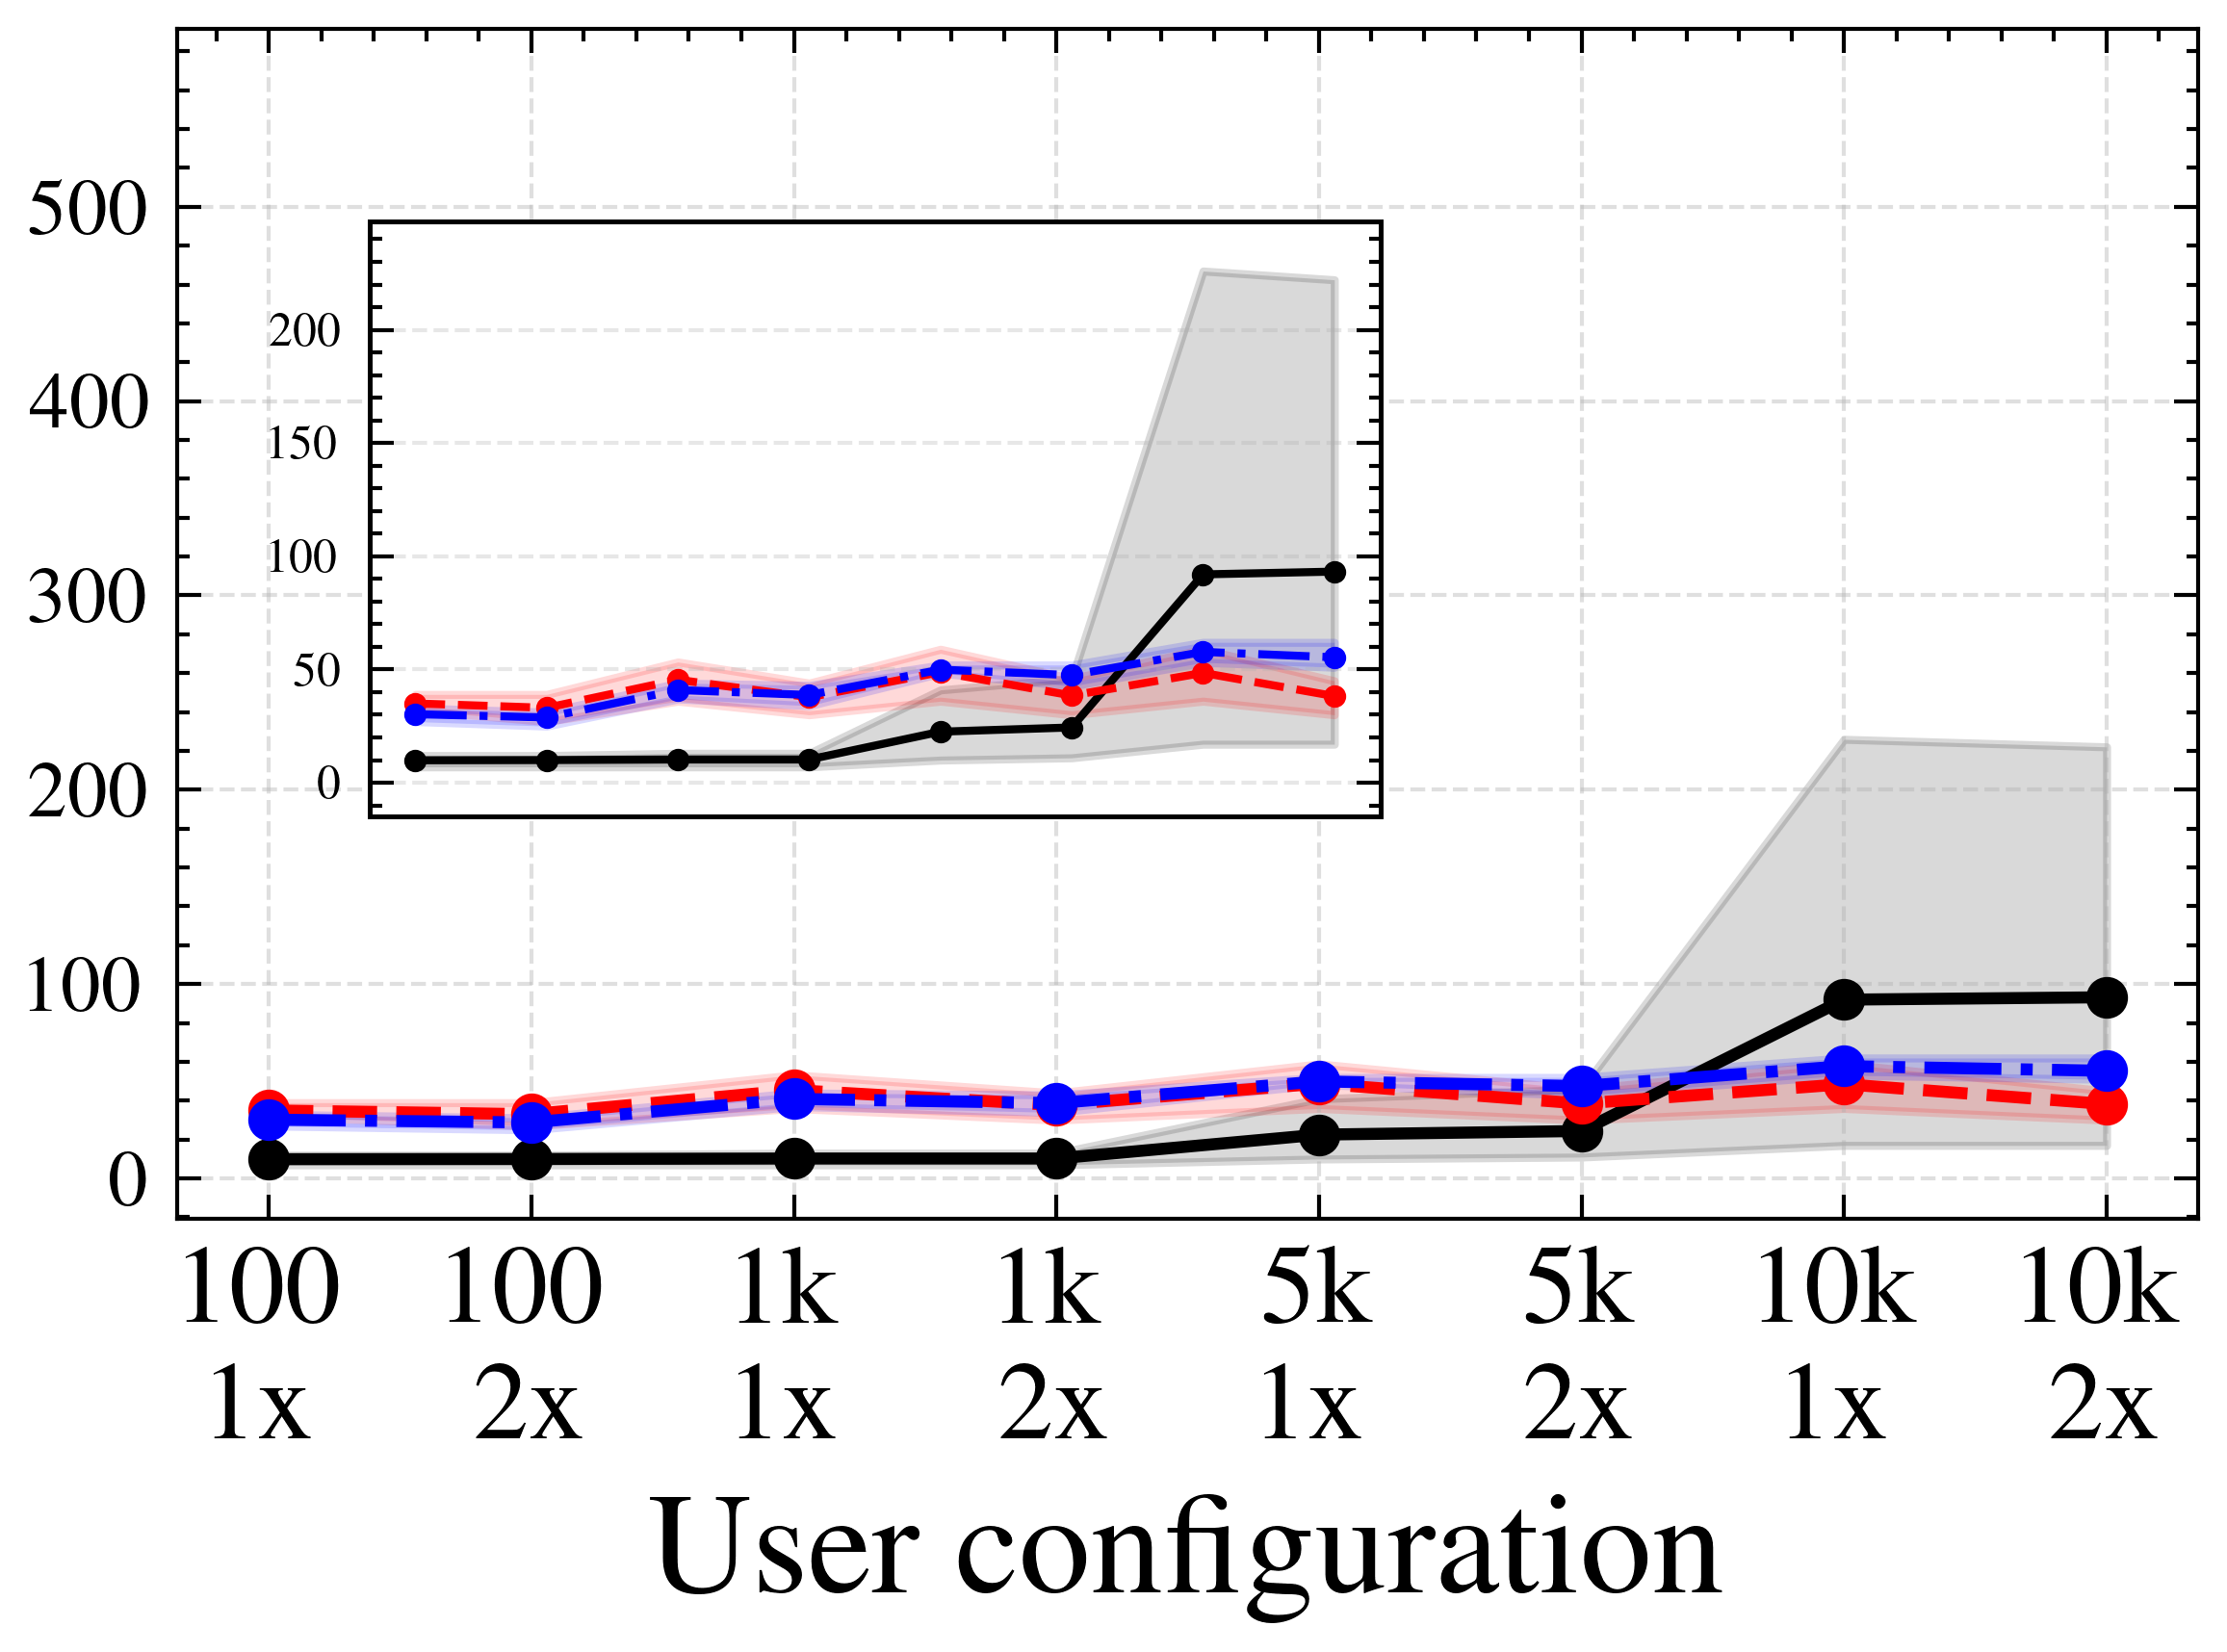

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_9245/3042910666.py:98: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Figure 3 — server 50x  →  px_latencies_p99_server_50x.pdf


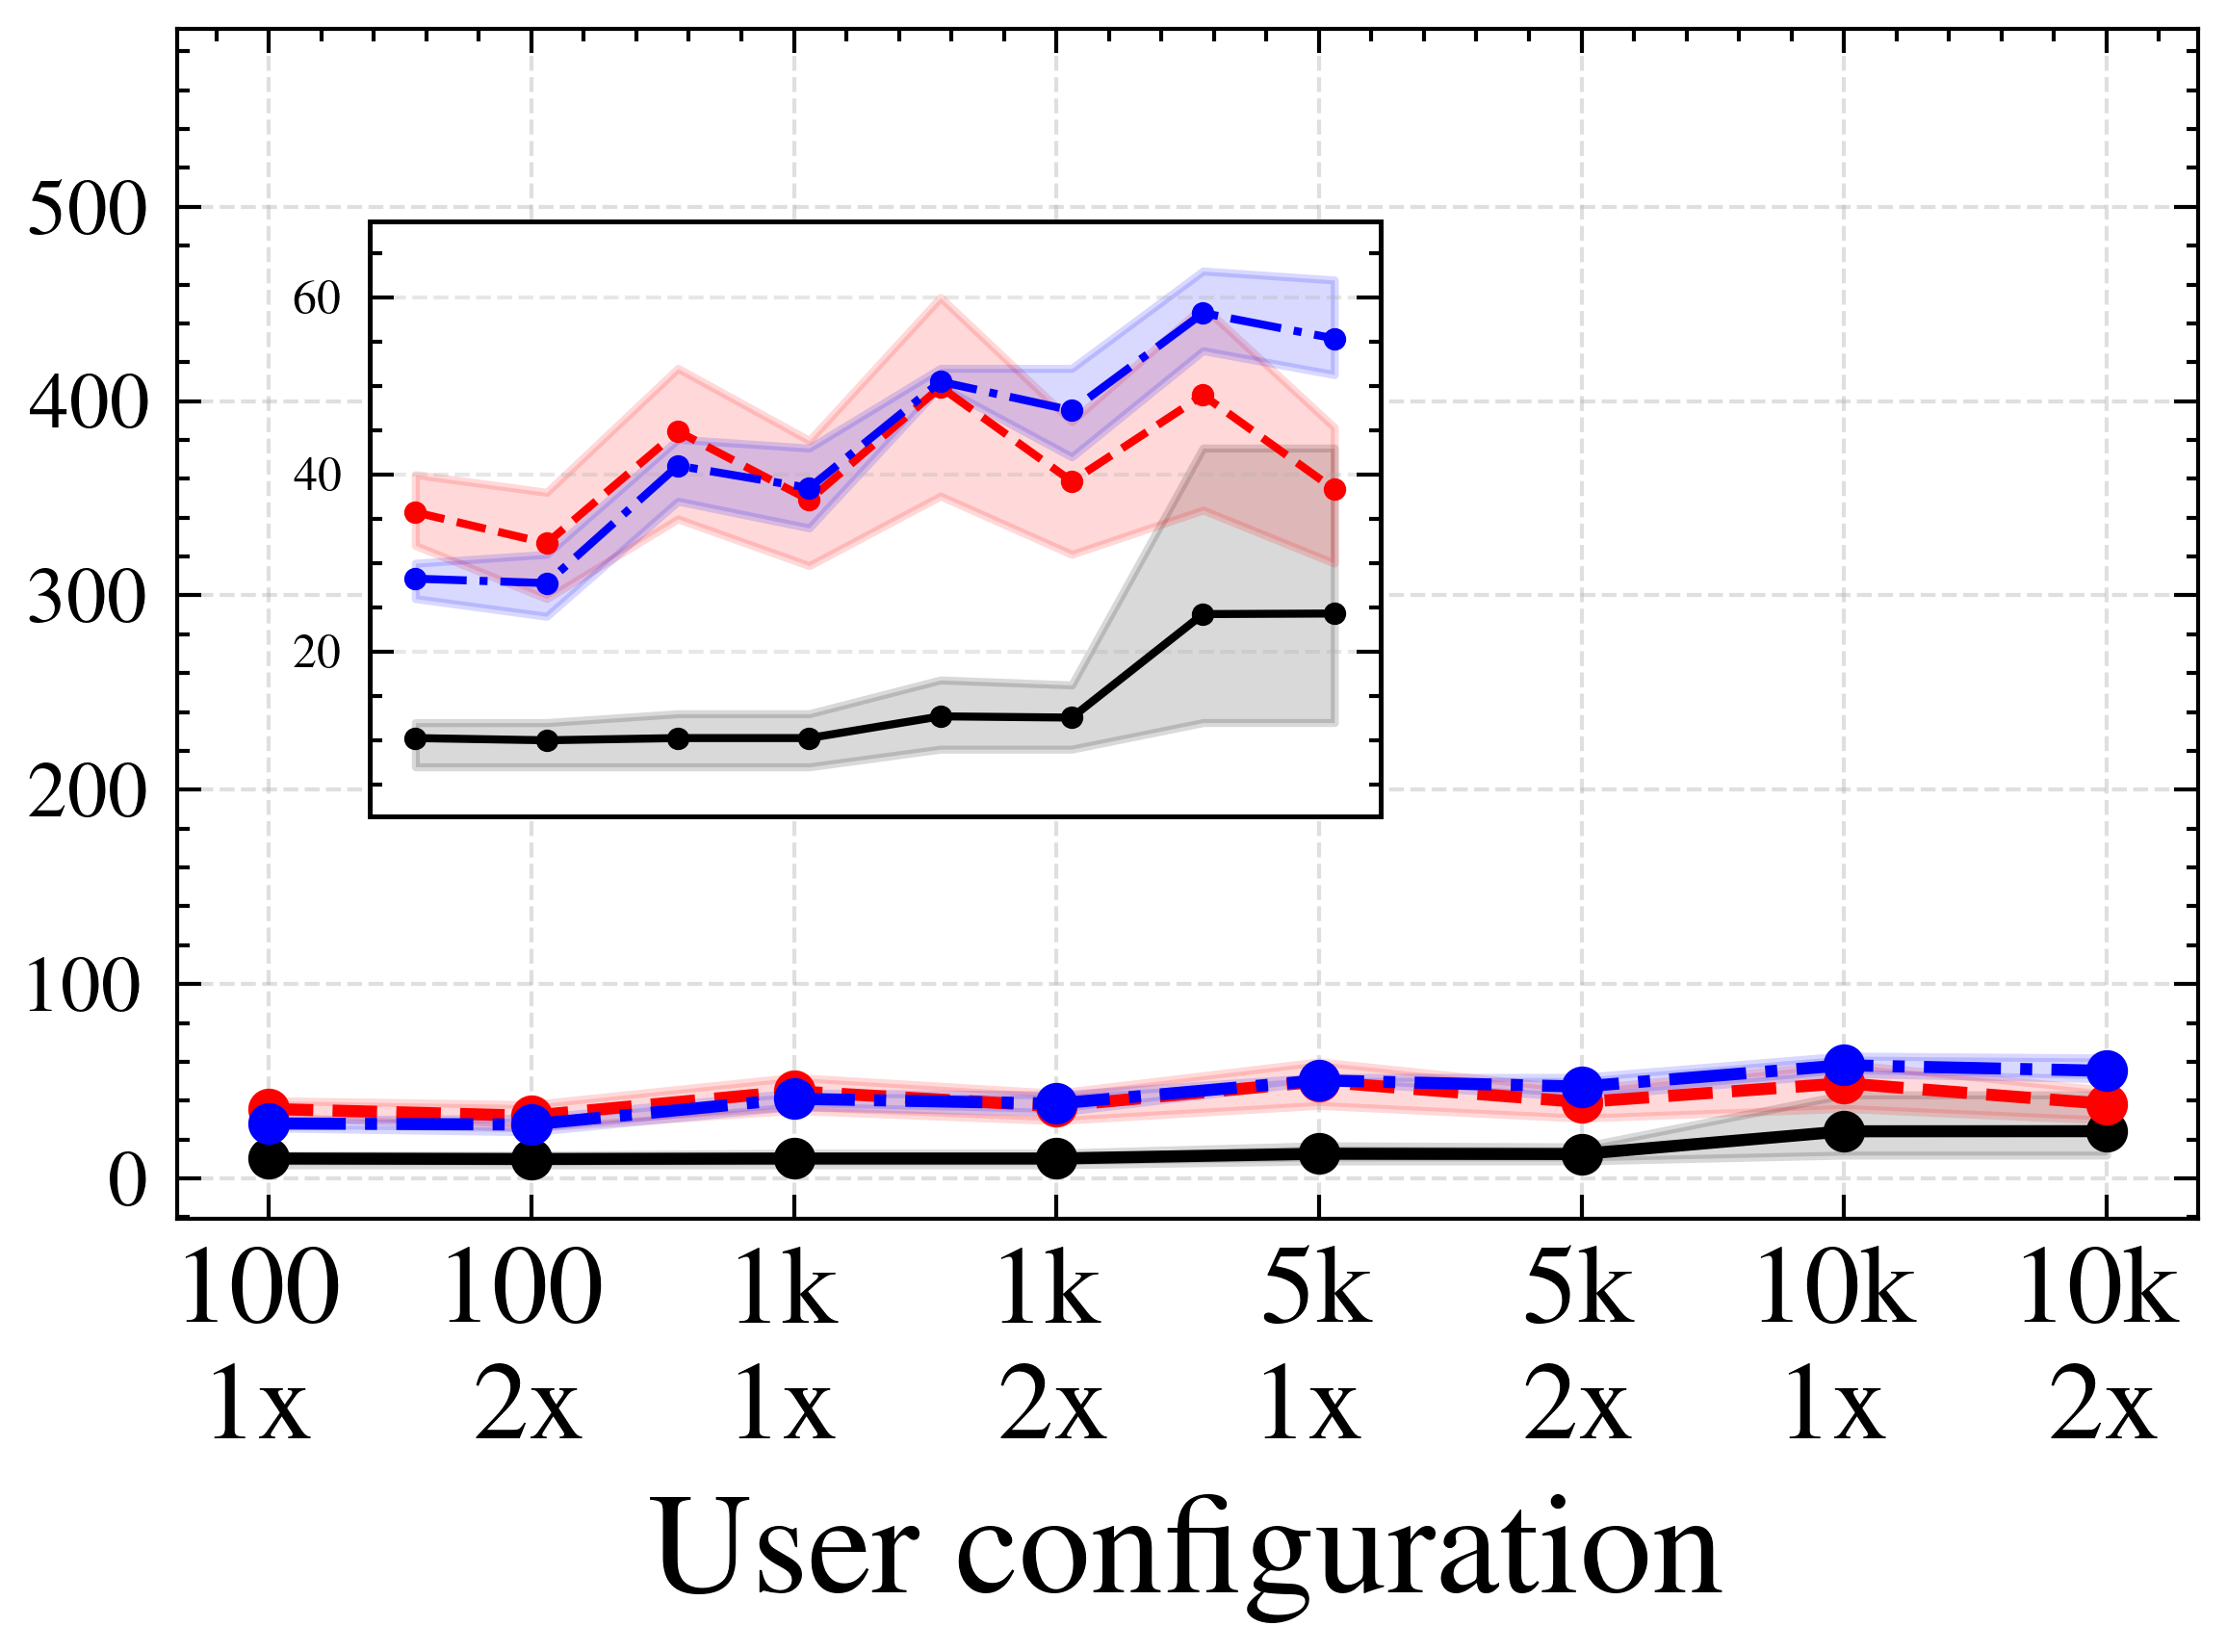

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_9245/3042910666.py:98: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Figure 4 — server 80x  →  px_latencies_p99_server_80x.pdf


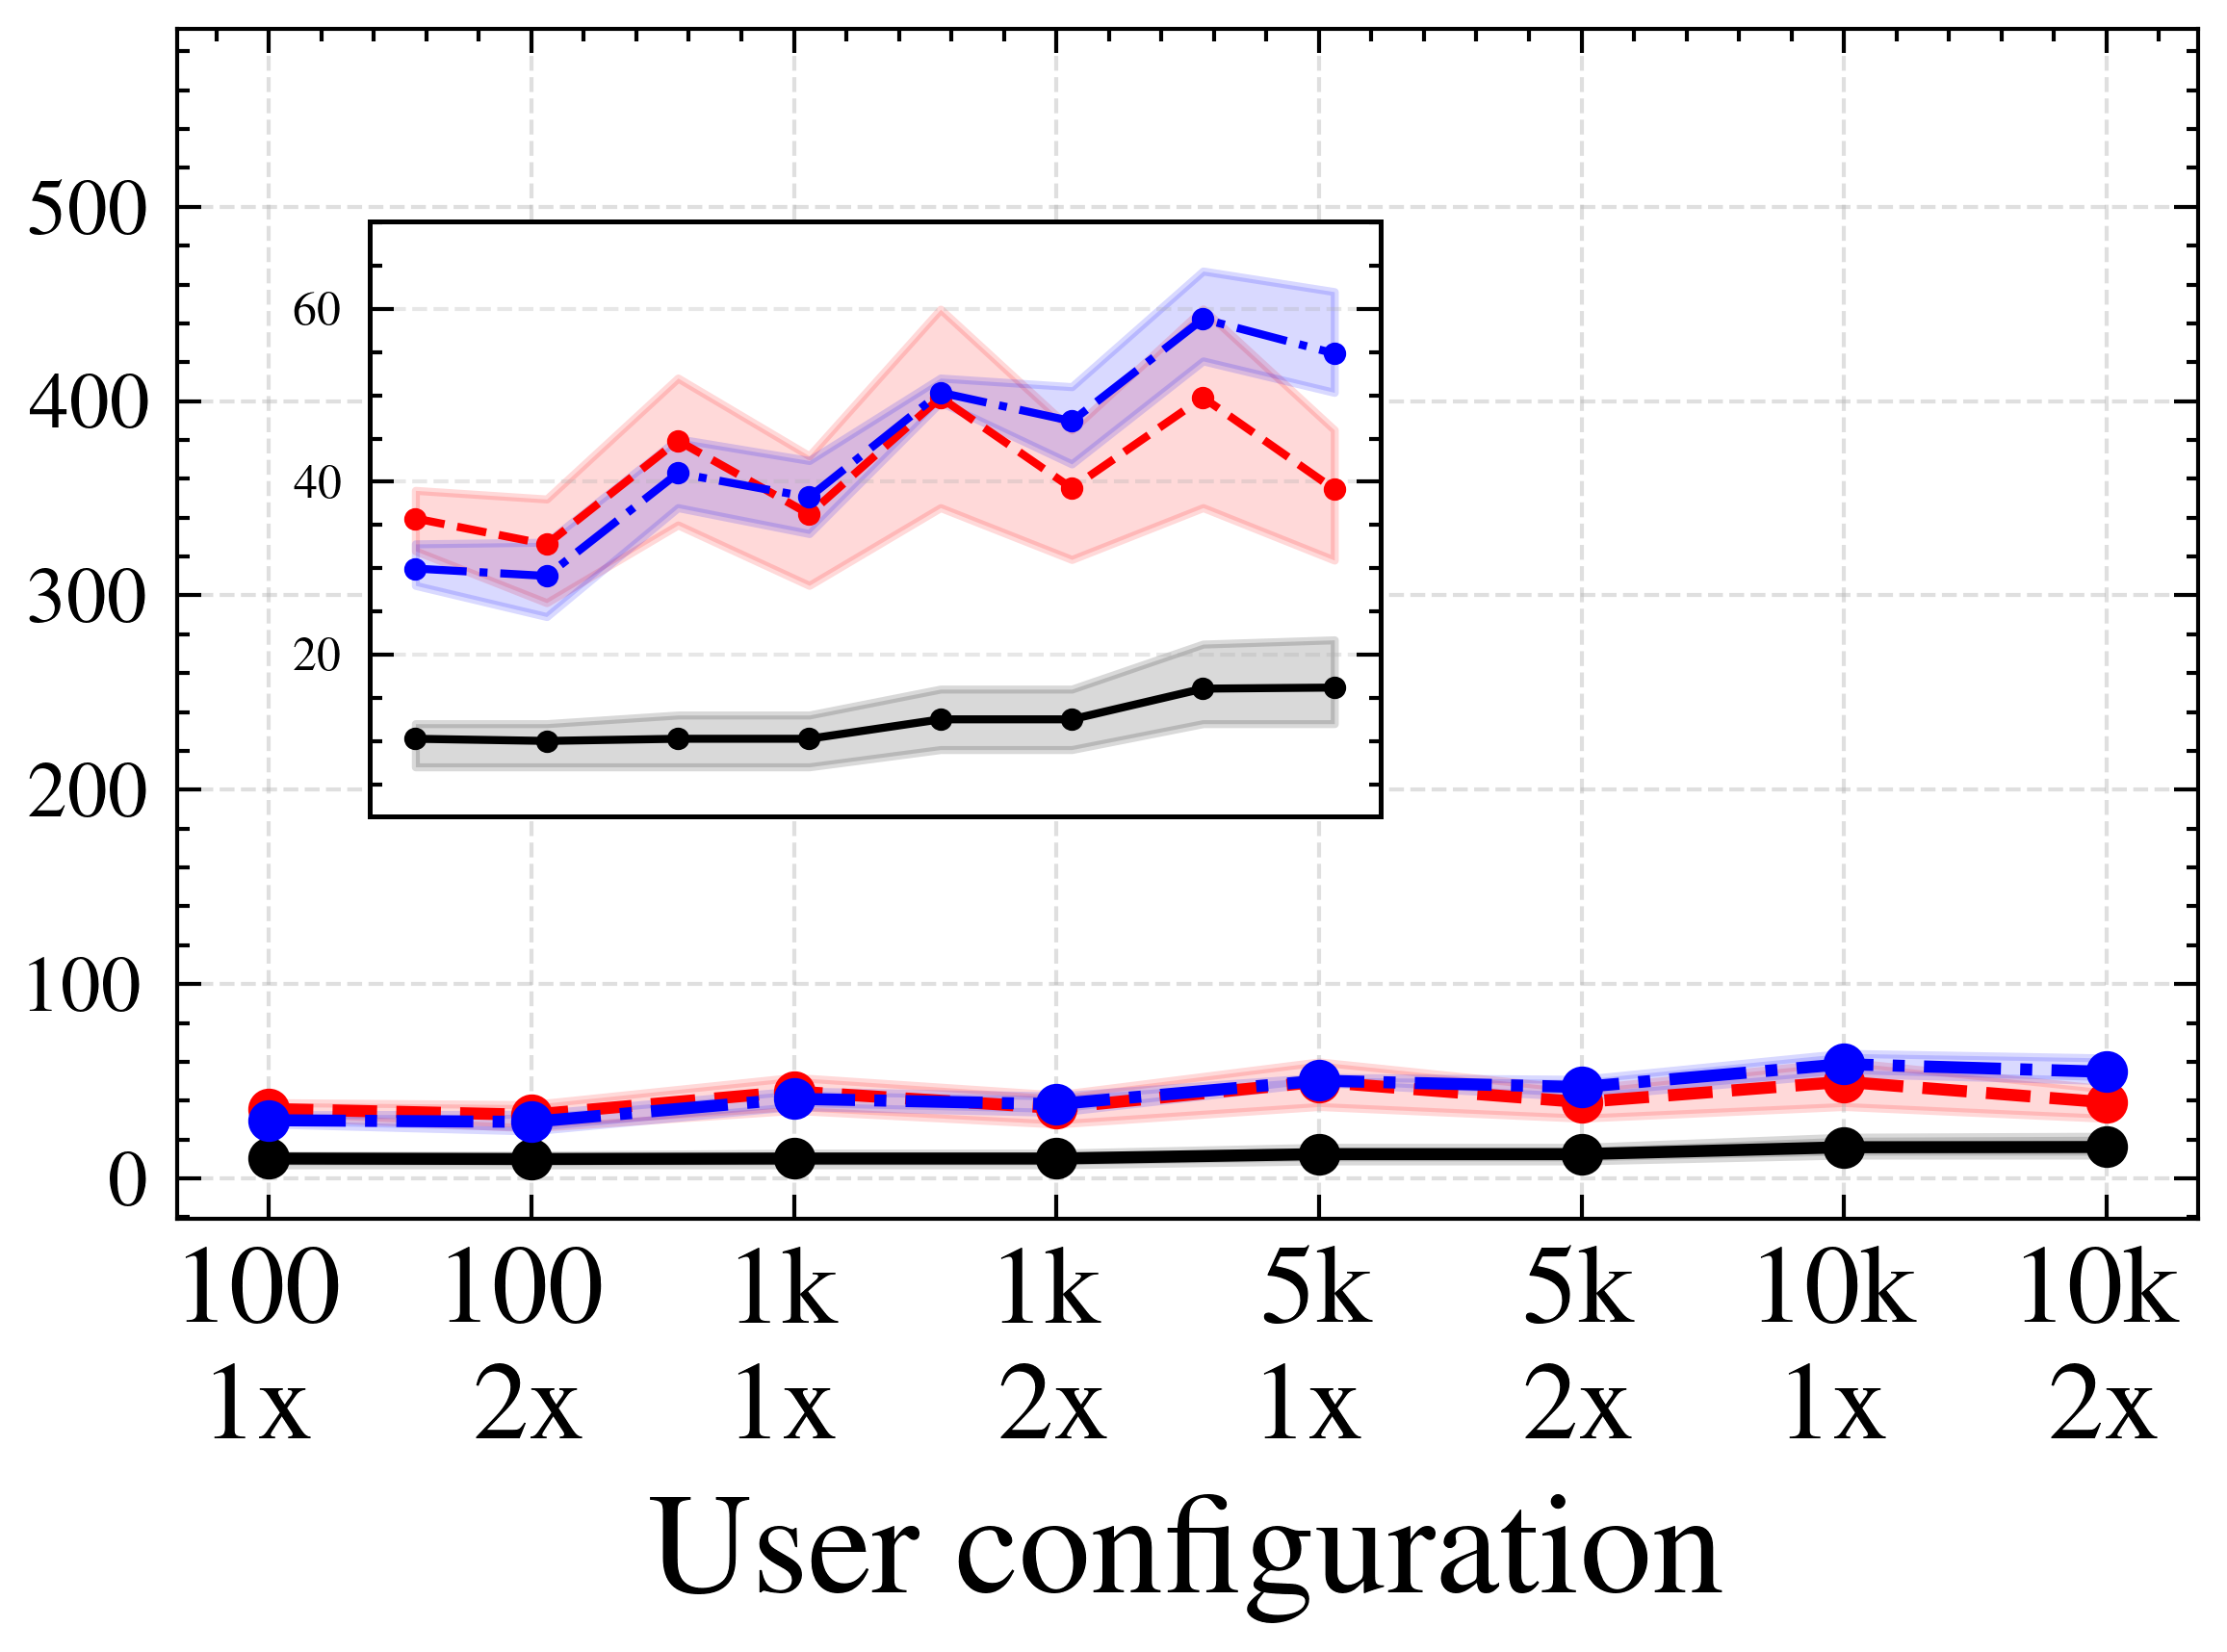

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_9245/3042910666.py:98: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Figure 5 — server 100x  →  px_latencies_p99_server_100x.pdf


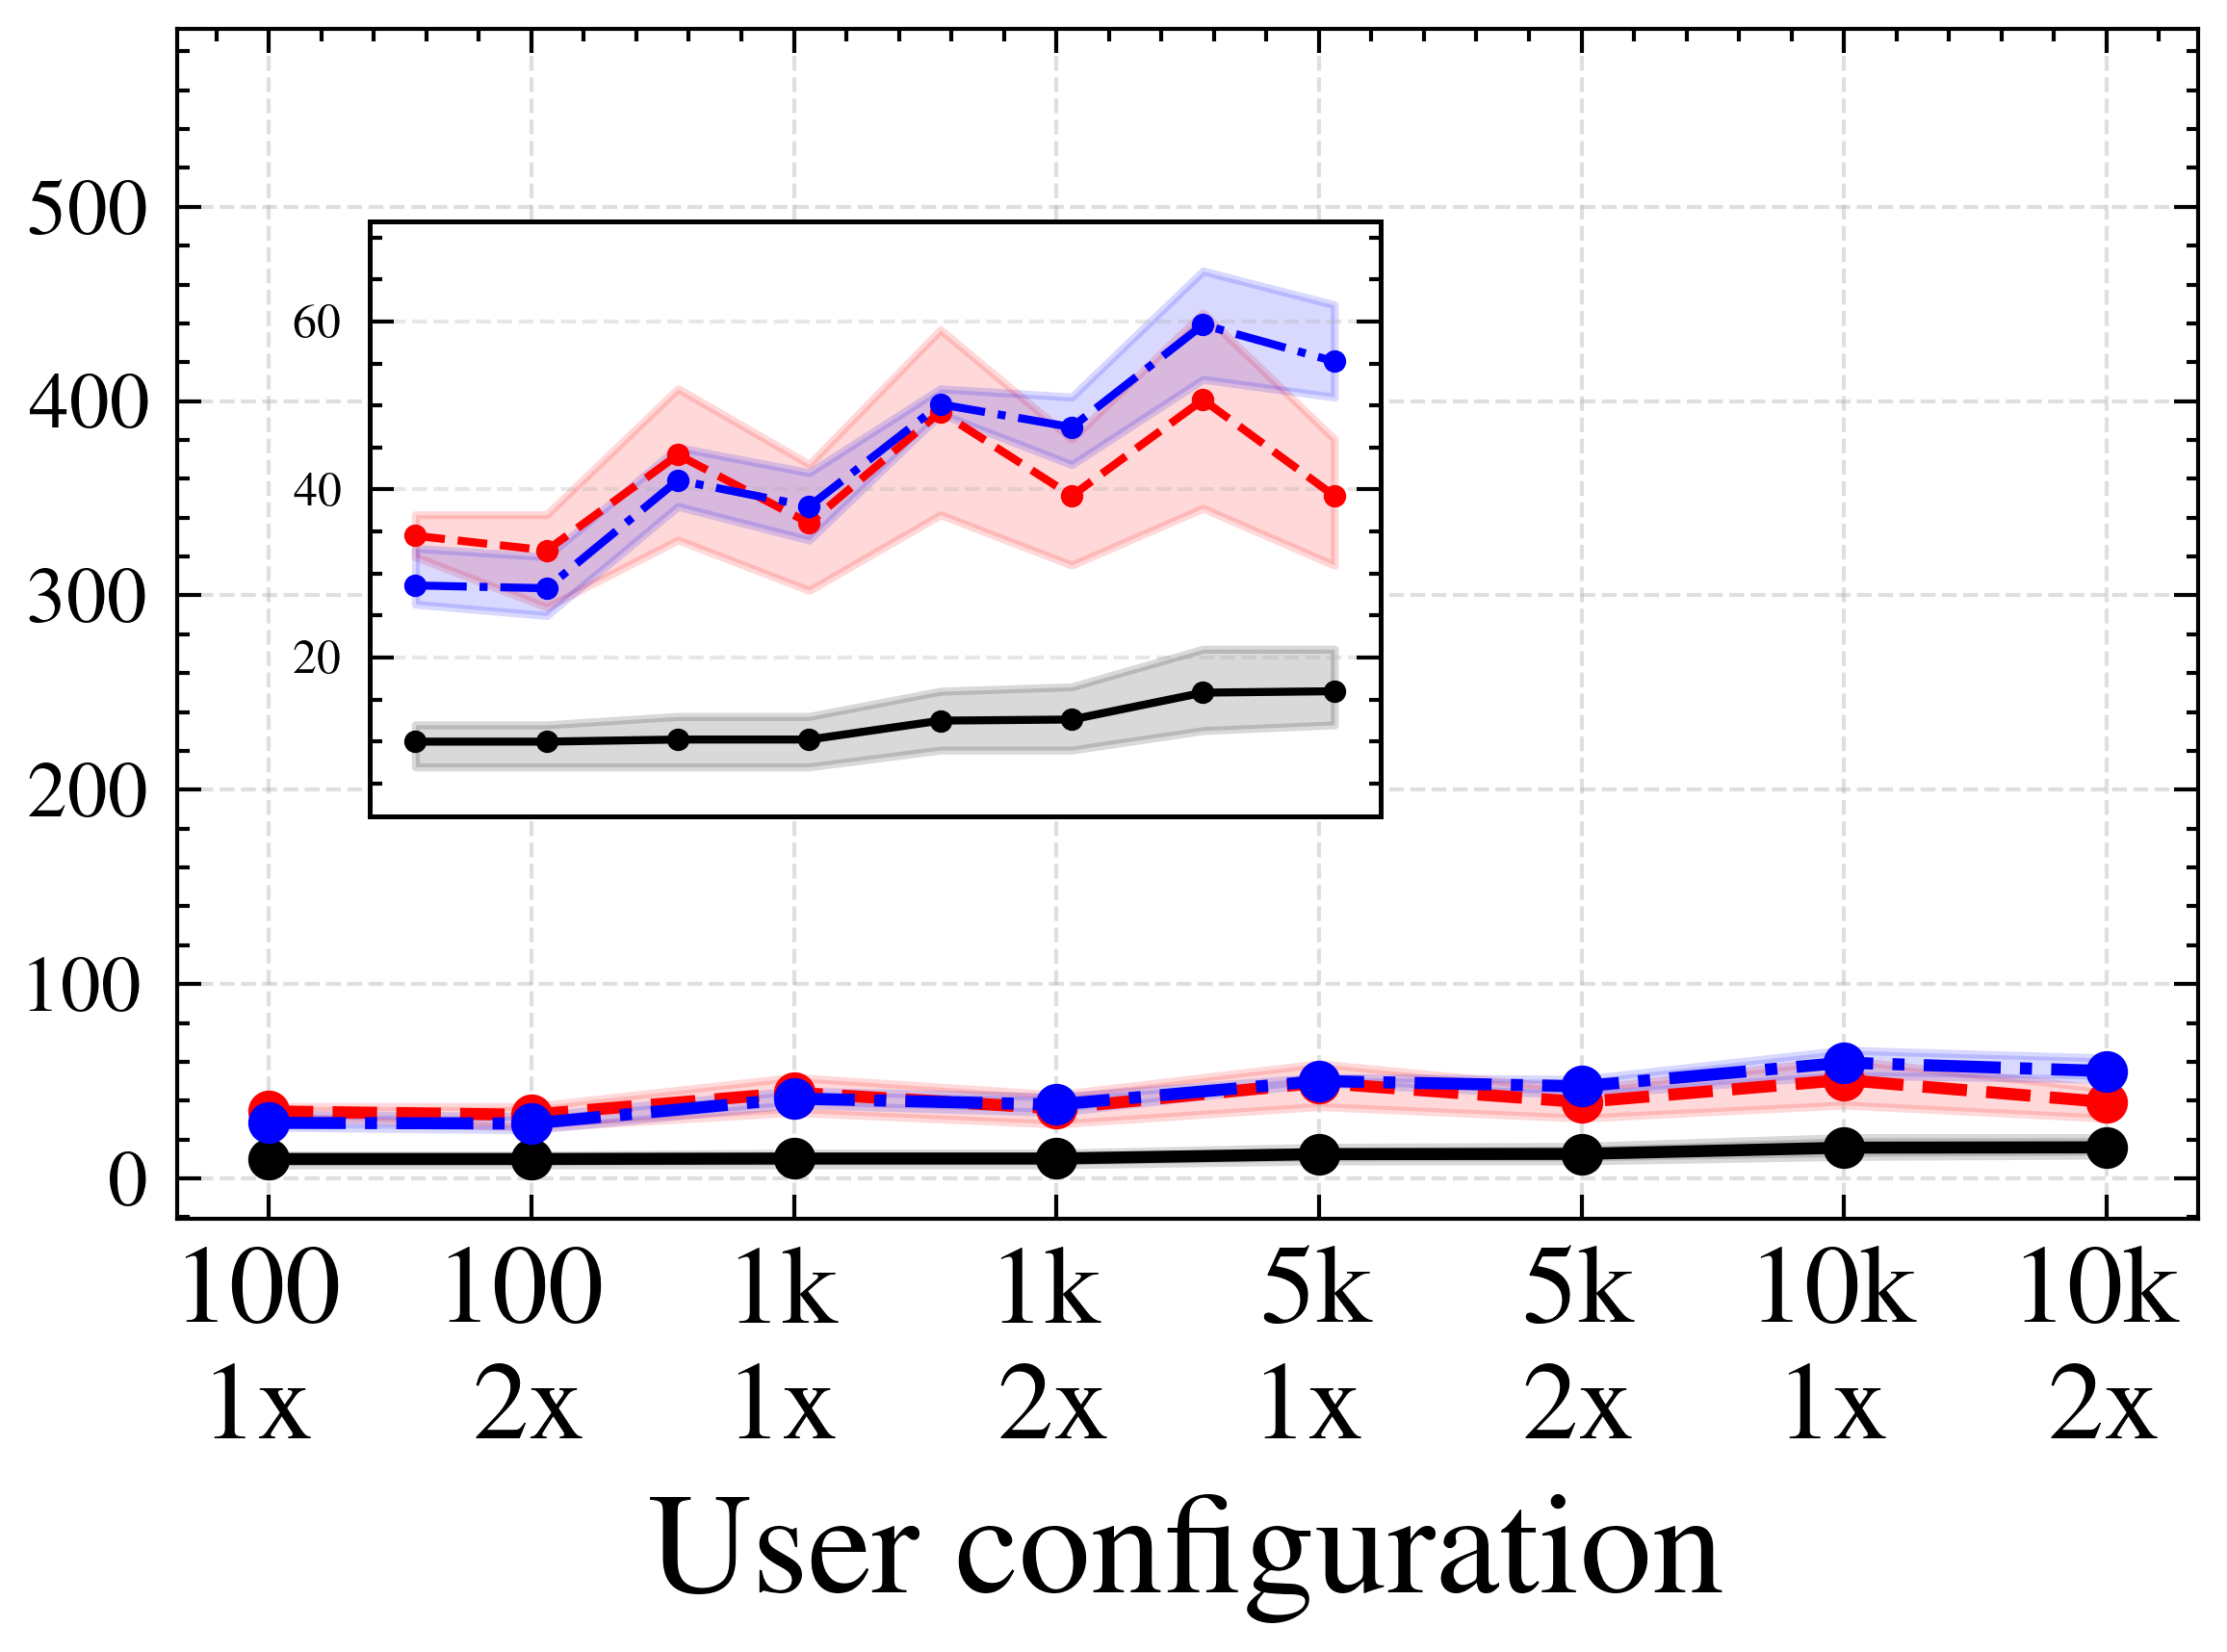

In [50]:
_theme_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
POLICY_COLORS = {policy: _theme_colors[i] for i, policy in enumerate(POLICIES)}

POLICY_LINESTYLES = {
    "centralized": "-",
    "default":     "--",
    "smart":       "-.",
    "smartx":      ":",
}

# _all_vals[(server_mult, t, policy)] = (p99_vals, cum_total_vals, cum_mean_vals) over x_configs
_all_vals = {}
for server_mult in server_mults:
    for t in range(n_tasks):
        for policy in POLICIES:
            p99_vals, cum_vals, mean_vals = [], [], []
            for n_clients, client_mult in x_configs:
                key = (policy, server_mult, n_clients, client_mult, t)
                if key in px_data:
                    entries = px_data[key]
                    p99_vals.append(np.mean([e[0] for e in entries]))
                    cum_vals.append(np.mean([e[1] for e in entries]))
                    mean_vals.append(np.mean([e[2] for e in entries]))
                else:
                    p99_vals.append(np.nan)
                    cum_vals.append(np.nan)
                    mean_vals.append(np.nan)
            _all_vals[(server_mult, t, policy)] = (p99_vals, cum_vals, mean_vals)

# Shared y-limits for p99 individual figures
_finite = [v for vals in _all_vals.values() for v in vals[0] if not np.isnan(v)]
_y_pad  = (max(_finite) - min(_finite)) * 0.05
_ylim_p99 = (min(_finite) - _y_pad, max(_finite) + _y_pad)

INSET_LOC = "upper left"  # adjust if it overlaps the lines/markers in a given figure

# Individual separate figures: one per server capacity, p99 shaded across request types
for i, server_mult in enumerate(server_mults):
    fig, ax = plt.subplots(figsize=(4, 3))

    policy_curves = {}
    for policy, policy_label in zip(POLICIES, POLICY_LABELS):
        color = POLICY_COLORS[policy]
        ls    = POLICY_LINESTYLES[policy]

        task_p99  = np.array([_all_vals[(server_mult, t, policy)][0] for t in range(n_tasks)])
        mean_vals = np.nanmean(task_p99, axis=0)
        min_vals  = np.nanmin(task_p99, axis=0)
        max_vals  = np.nanmax(task_p99, axis=0)
        policy_curves[policy] = (mean_vals, min_vals, max_vals)

        ax.plot(x_pos, mean_vals, color=color, linestyle=ls, marker="o",
                markersize=4, markeredgewidth=1.2, linewidth=1.5, label=policy_label)
        ax.fill_between(x_pos, min_vals, max_vals, color=color, alpha=0.15)

    ax.set_ylim(_ylim_p99)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, fontsize=14)
    ax.tick_params(axis="y", labelsize=10)
    ax.tick_params(axis="x", which="minor", bottom=False)
    ax.set_xlabel("User configuration", fontsize=18)
    ax.grid(True, linestyle="--", alpha=0.4)

    if i == 0:
        ax.set_ylabel("P99 latency (s)", fontsize=18)
        ax.legend(fontsize=10.5, loc="upper left", ncol=1)

    # Zoomed inset on this figure's own y-range, so small variations stay visible
    # even though the main (outer) y-axis stays shared across all figures.
    if i > 0:
        inset_ax = inset_axes(ax, width="50%", height="50%", loc=INSET_LOC, borderpad=3.0)

        local_vals = np.concatenate([
            np.concatenate([mean_vals, min_vals, max_vals])
            for mean_vals, min_vals, max_vals in policy_curves.values()
        ])
        local_vals = local_vals[np.isfinite(local_vals)]
        y_span = local_vals.max() - local_vals.min()
        y_pad  = y_span * 0.1 if y_span > 0 else local_vals.max() * 0.05
        inset_ax.set_ylim(local_vals.min() - y_pad, local_vals.max() + y_pad)

        for policy, policy_label in zip(POLICIES, POLICY_LABELS):
            color = POLICY_COLORS[policy]
            ls    = POLICY_LINESTYLES[policy]
            mean_vals, min_vals, max_vals = policy_curves[policy]

            inset_ax.plot(x_pos, mean_vals, color=color, linestyle=ls,
                           marker="o", markersize=2, markeredgewidth=0.8, linewidth=1.0)
            inset_ax.fill_between(x_pos, min_vals, max_vals, color=color, alpha=0.15)

        inset_ax.set_xticks([])
        inset_ax.tick_params(axis="y", labelsize=6)
        inset_ax.grid(True, linestyle="--", alpha=0.3)
        for spine in inset_ax.spines.values():
            spine.set_linewidth(0.6)

    fname = f"px_latencies_p99_server_{server_mult}x.pdf"
    plt.tight_layout()
    plt.savefig(os.path.join(figures_dir, fname), bbox_inches="tight")
    print(f"Figure {i + 1} — server {server_mult}x  →  {fname}")
    plt.show()

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_9245/975794334.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


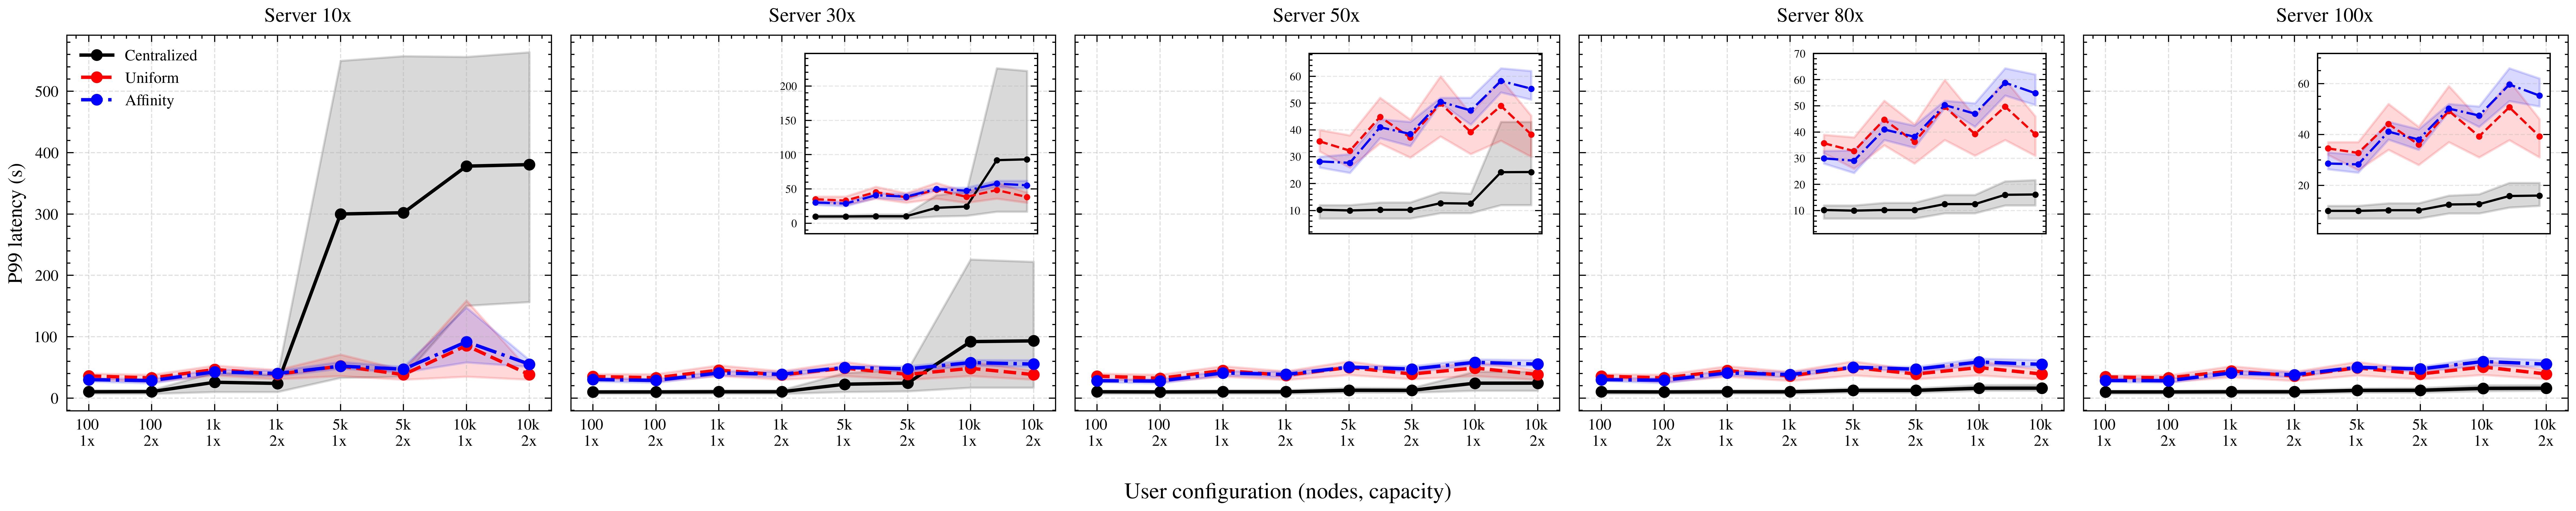

In [51]:
INSET_LOC = "upper right"  # adjust if it overlaps the lines/markers in a given subplot

fig, axes = plt.subplots(
    1, len(server_mults),
    figsize=(3.2 * len(server_mults), 3.2),
    sharex=True,
    sharey=True
)

for col, server_mult in enumerate(server_mults):
    ax = axes[col]

    policy_curves = {}
    for policy, policy_label in zip(POLICIES, POLICY_LABELS):
        color = POLICY_COLORS[policy]
        ls    = POLICY_LINESTYLES[policy]

        task_p99  = np.array([_all_vals[(server_mult, t, policy)][0] for t in range(n_tasks)])
        mean_vals = np.nanmean(task_p99, axis=0)
        min_vals  = np.nanmin(task_p99, axis=0)
        max_vals  = np.nanmax(task_p99, axis=0)
        policy_curves[policy] = (mean_vals, min_vals, max_vals)

        ax.plot(x_pos, mean_vals, color=color, linestyle=ls,
                marker="o", markersize=4, markeredgewidth=1.2,
                linewidth=1.5, label=policy_label)
        ax.fill_between(x_pos, min_vals, max_vals, color=color, alpha=0.15)

    ax.set_title(f"Server {server_mult}x", fontsize=9, fontweight="bold")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, fontsize=7)
    ax.tick_params(axis="y", labelsize=7)
    ax.tick_params(axis="x", which="minor", bottom=False)
    ax.grid(True, linestyle="--", alpha=0.4)

    # Zoomed inset on this subplot's own y-range, so small variations stay visible
    # even though the main (outer) y-axis stays shared across all subplots.
    if col > 0:
        inset_ax = inset_axes(ax, width="48%", height="48%", loc=INSET_LOC, borderpad=1.0)

        local_vals = np.concatenate([
            np.concatenate([mean_vals, min_vals, max_vals])
            for mean_vals, min_vals, max_vals in policy_curves.values()
        ])
        local_vals = local_vals[np.isfinite(local_vals)]
        y_span = local_vals.max() - local_vals.min()
        y_pad  = y_span * 0.1 if y_span > 0 else local_vals.max() * 0.05
        inset_ax.set_ylim(local_vals.min() - y_pad, local_vals.max() + y_pad)

        for policy, policy_label in zip(POLICIES, POLICY_LABELS):
            color = POLICY_COLORS[policy]
            ls    = POLICY_LINESTYLES[policy]
            mean_vals, min_vals, max_vals = policy_curves[policy]

            inset_ax.plot(x_pos, mean_vals, color=color, linestyle=ls,
                           marker="o", markersize=2, markeredgewidth=0.8, linewidth=1.0)
            inset_ax.fill_between(x_pos, min_vals, max_vals, color=color, alpha=0.15)

        inset_ax.set_xticks([])
        inset_ax.tick_params(axis="y", labelsize=5)
        inset_ax.grid(True, linestyle="--", alpha=0.3)
        for spine in inset_ax.spines.values():
            spine.set_linewidth(0.6)

axes[0].set_ylabel("P99 latency (s)", fontsize=9)
axes[0].legend(fontsize=7, loc="upper left")

fig.supxlabel("User configuration (nodes, capacity)", fontsize=10, y=0.01)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "px_latencies_p99_grid.pdf"), bbox_inches="tight")
plt.show()

Figure 1 — server 10x  →  cum_total_latency_server_10x.pdf


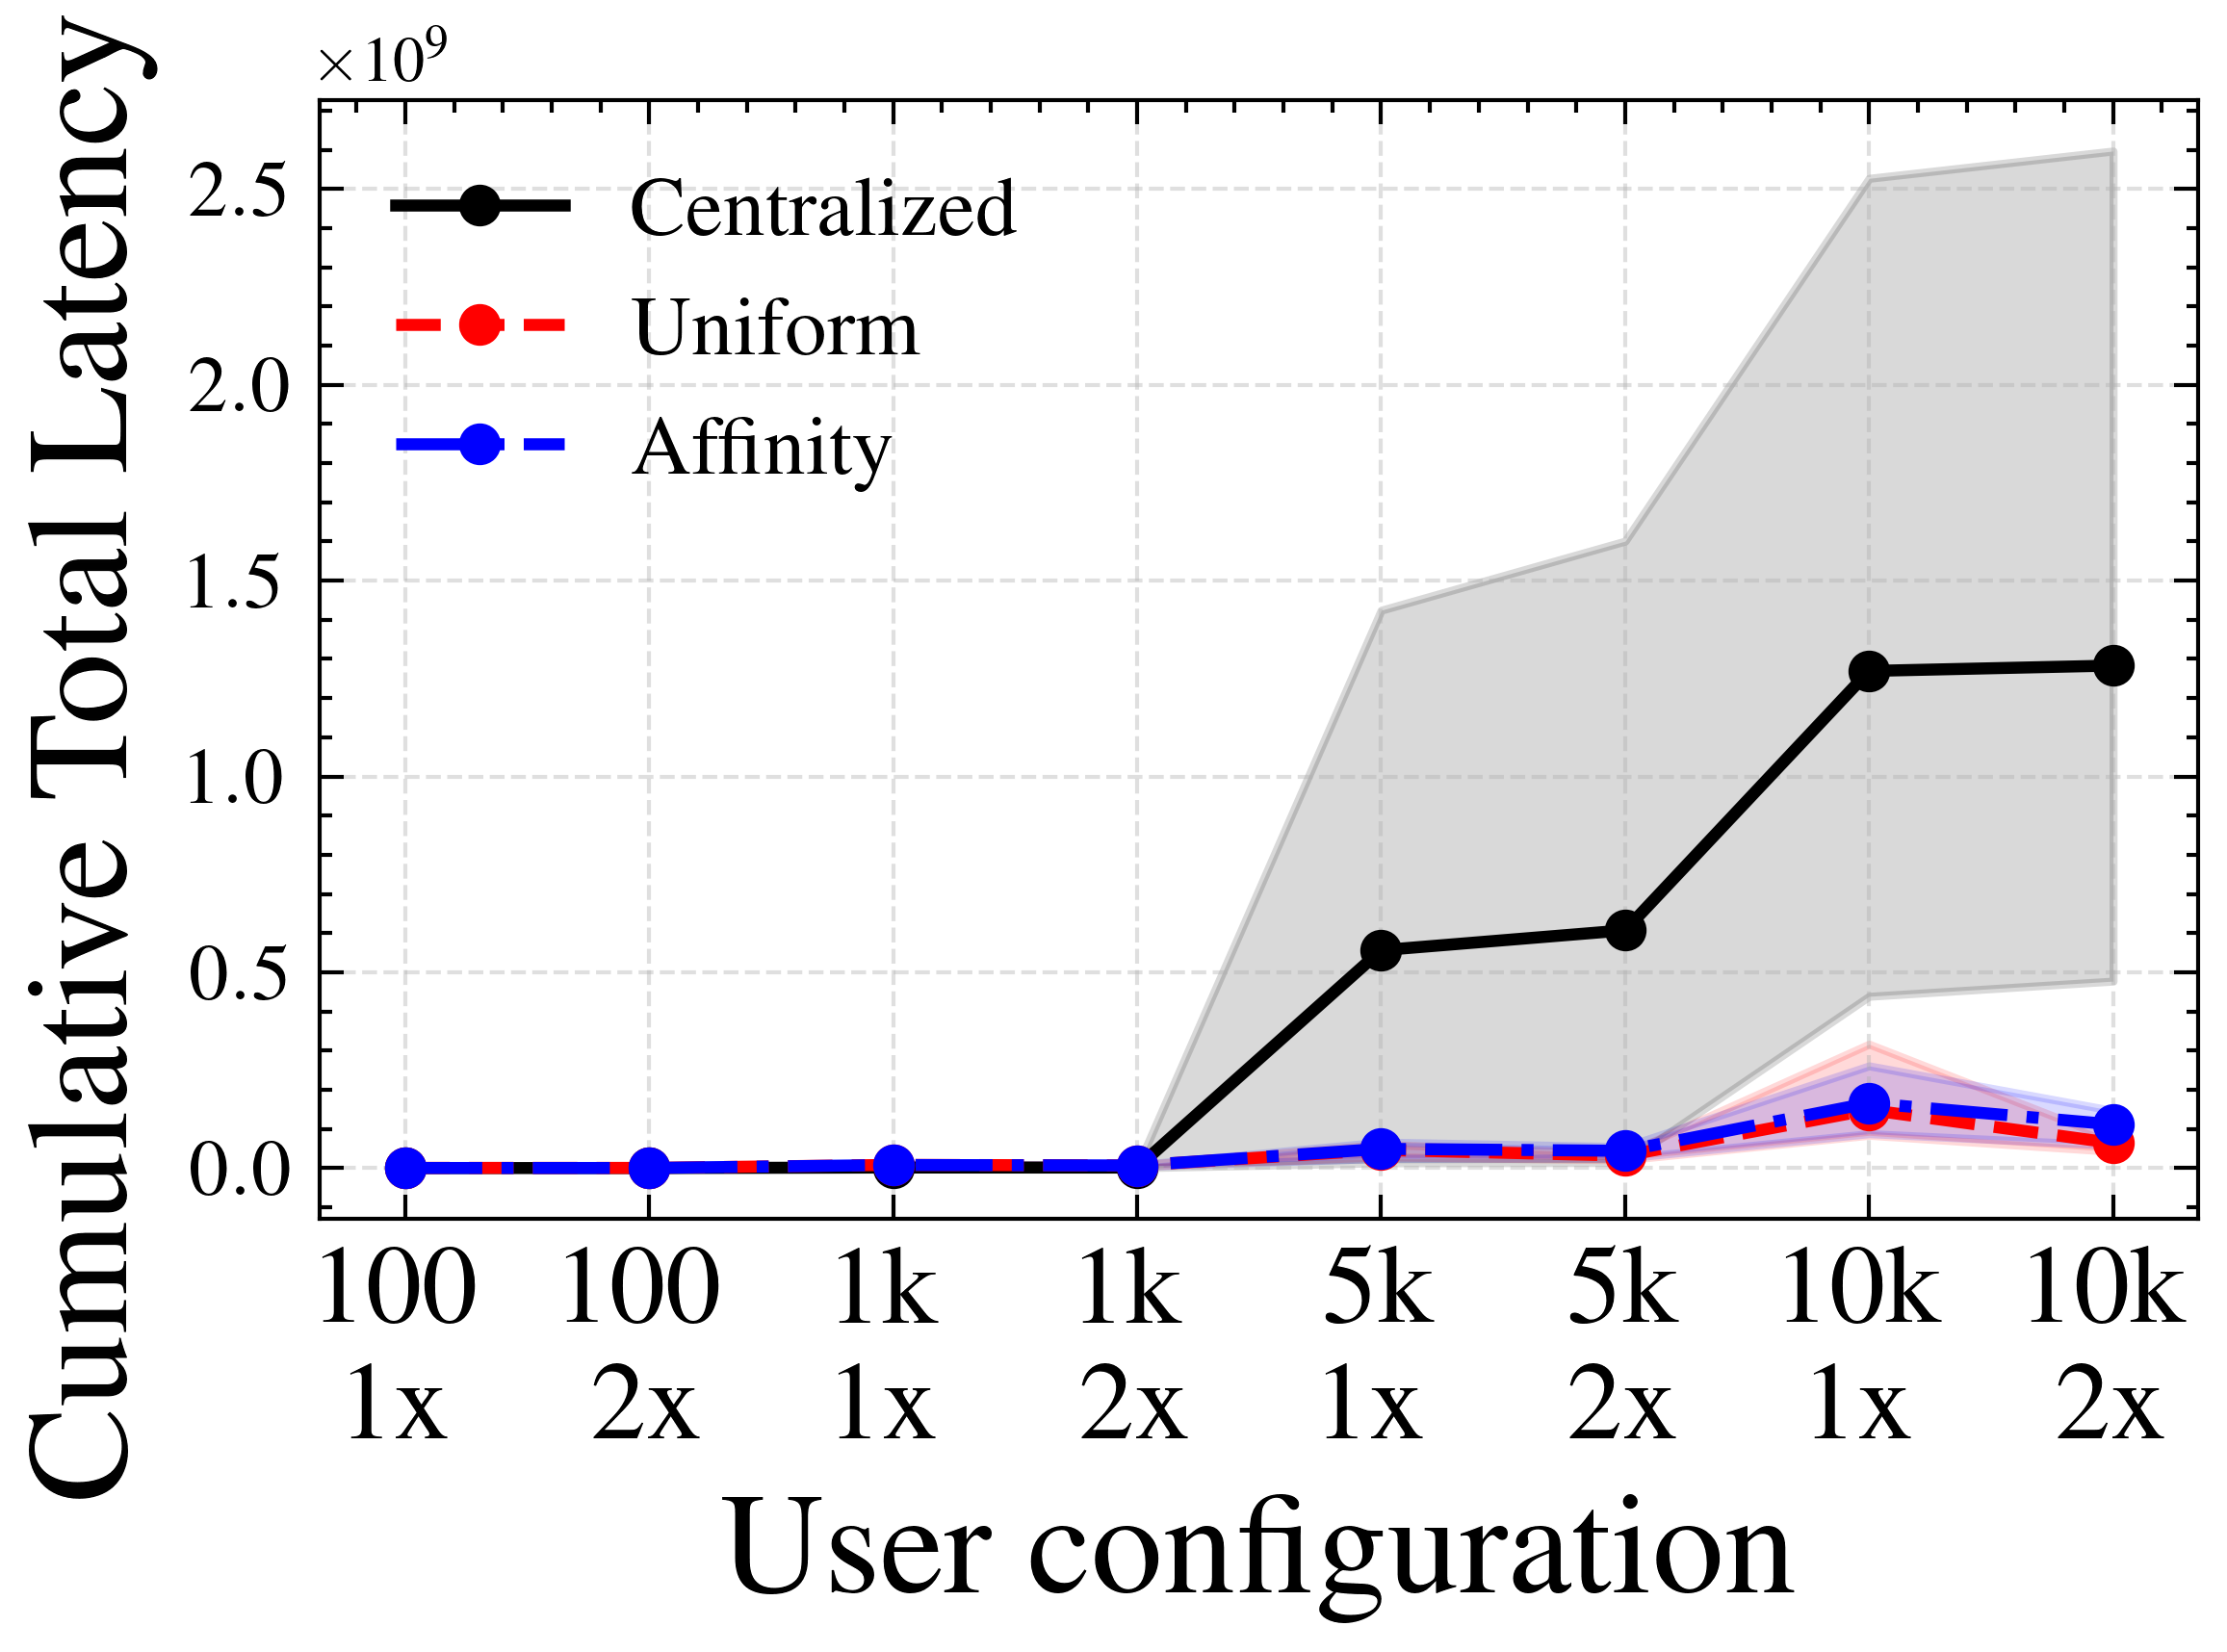

Figure 2 — server 30x  →  cum_total_latency_server_30x.pdf


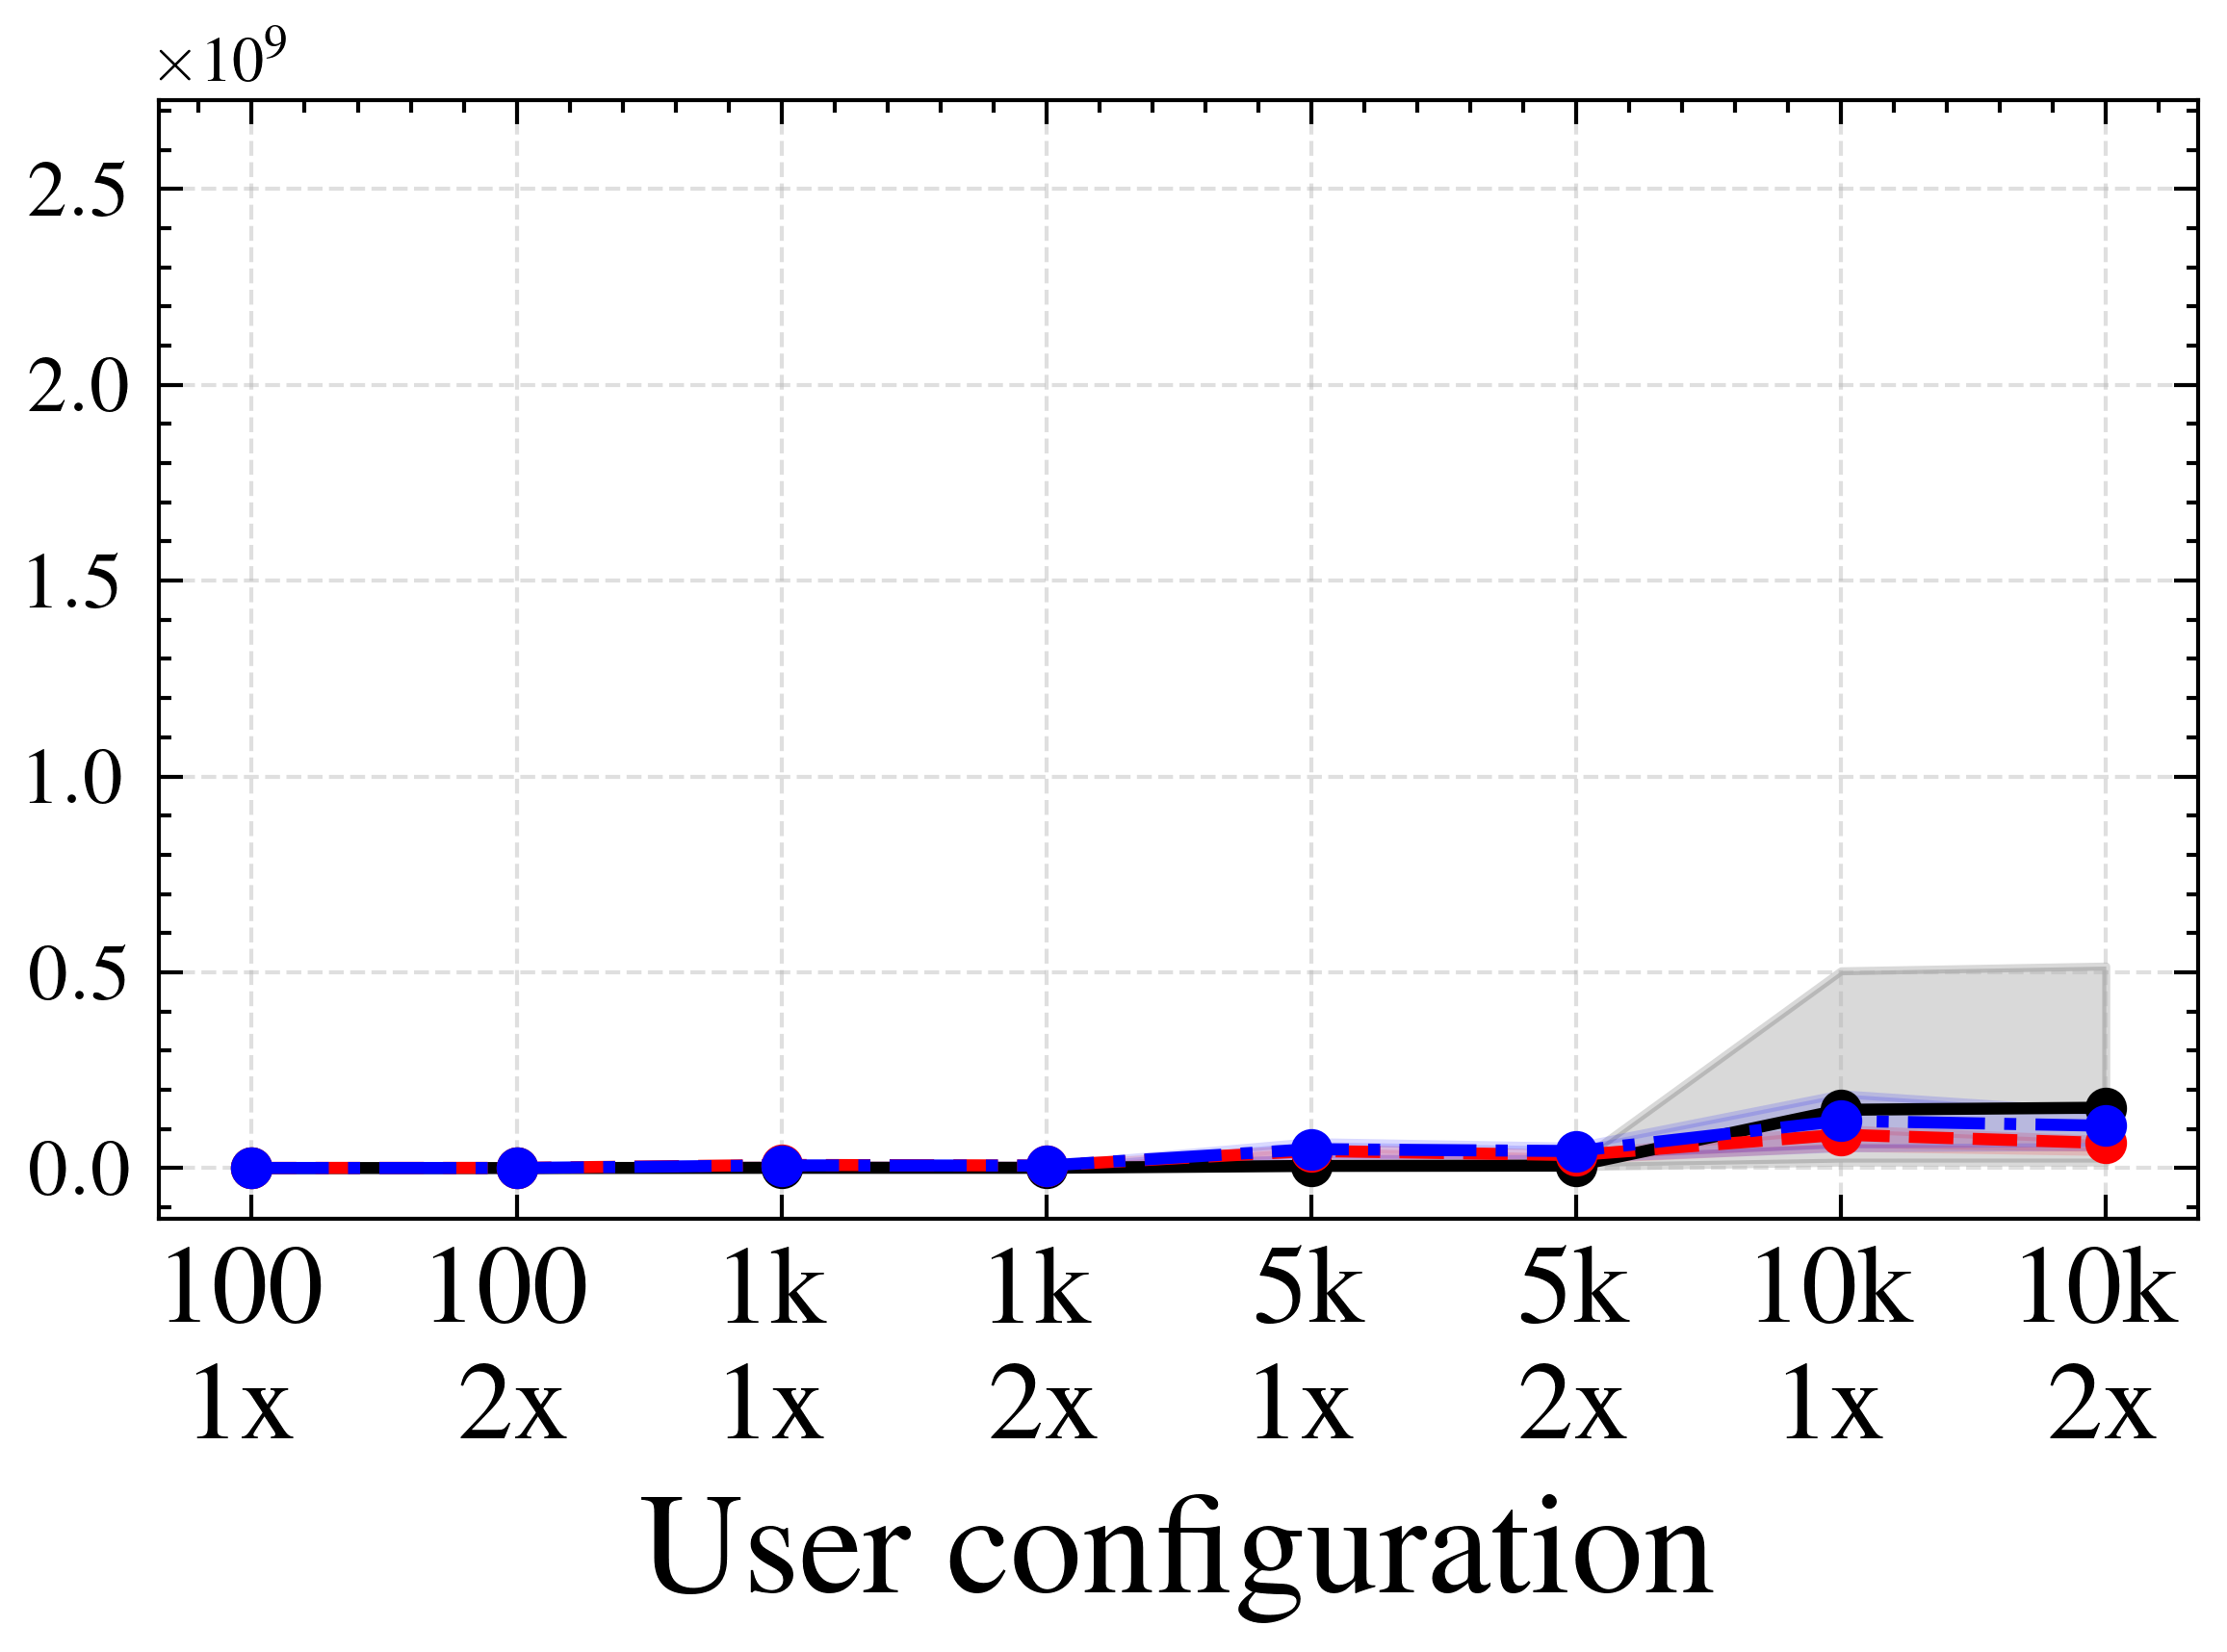

Figure 3 — server 50x  →  cum_total_latency_server_50x.pdf


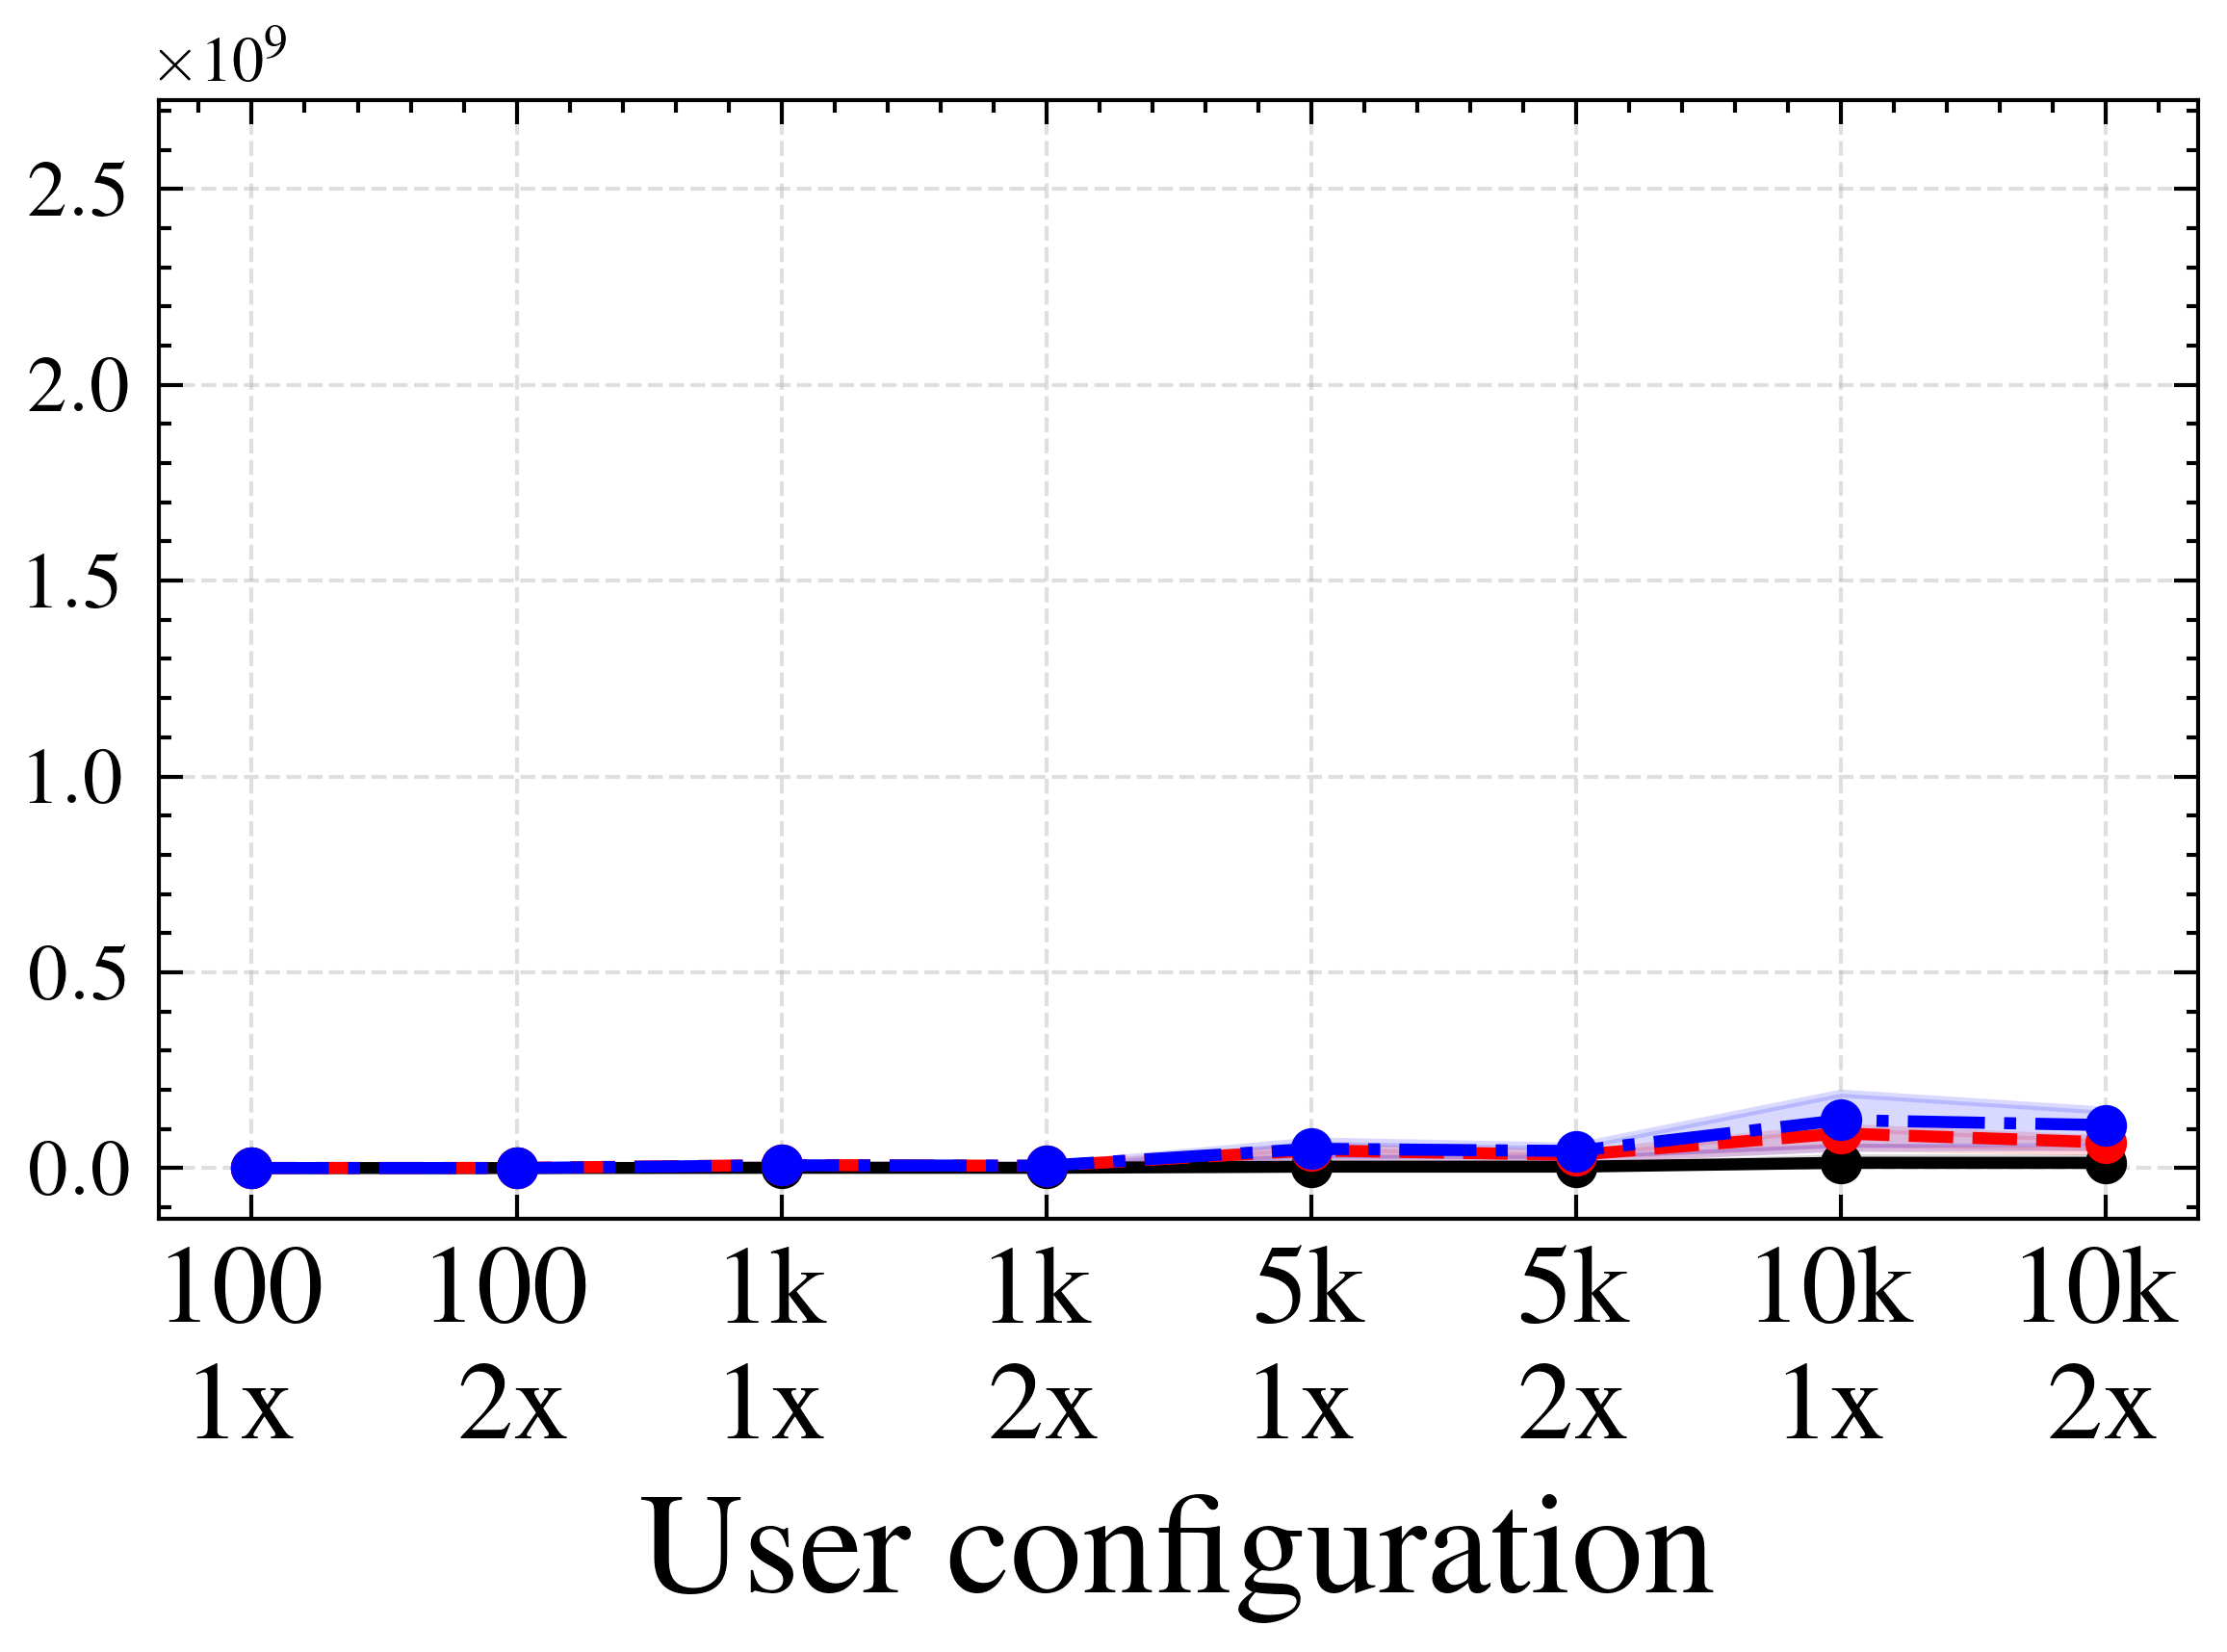

Figure 4 — server 80x  →  cum_total_latency_server_80x.pdf


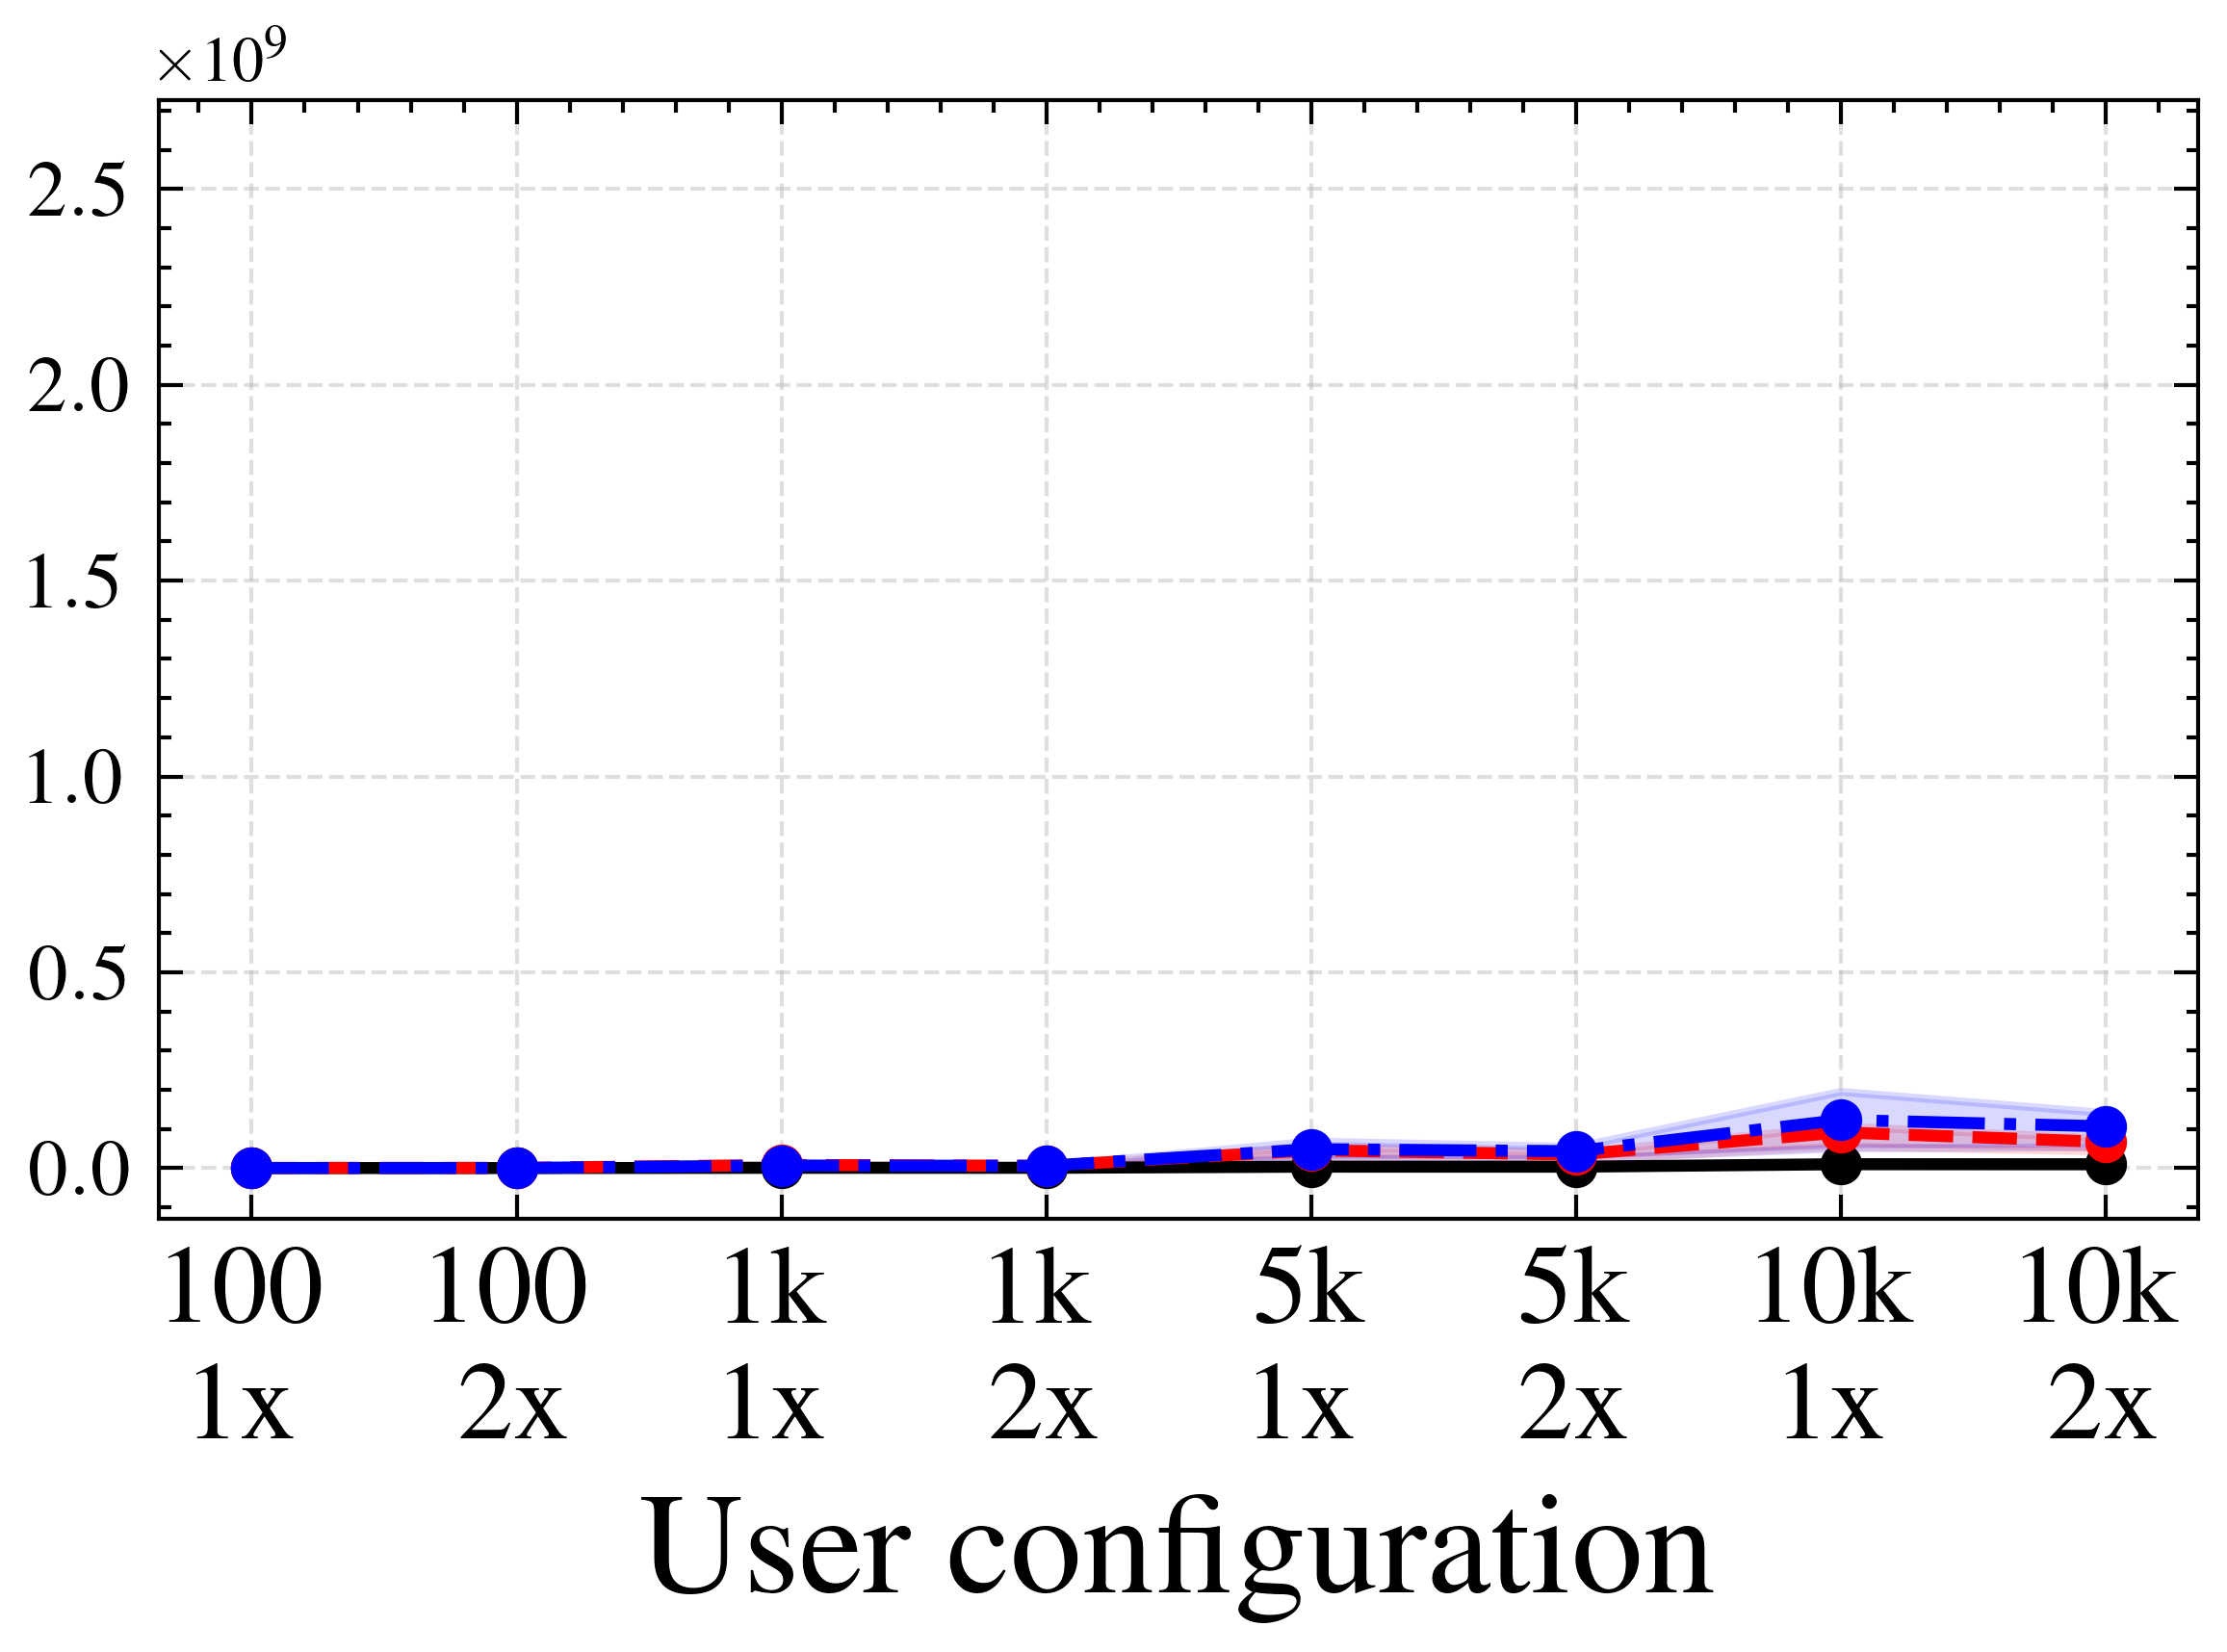

Figure 5 — server 100x  →  cum_total_latency_server_100x.pdf


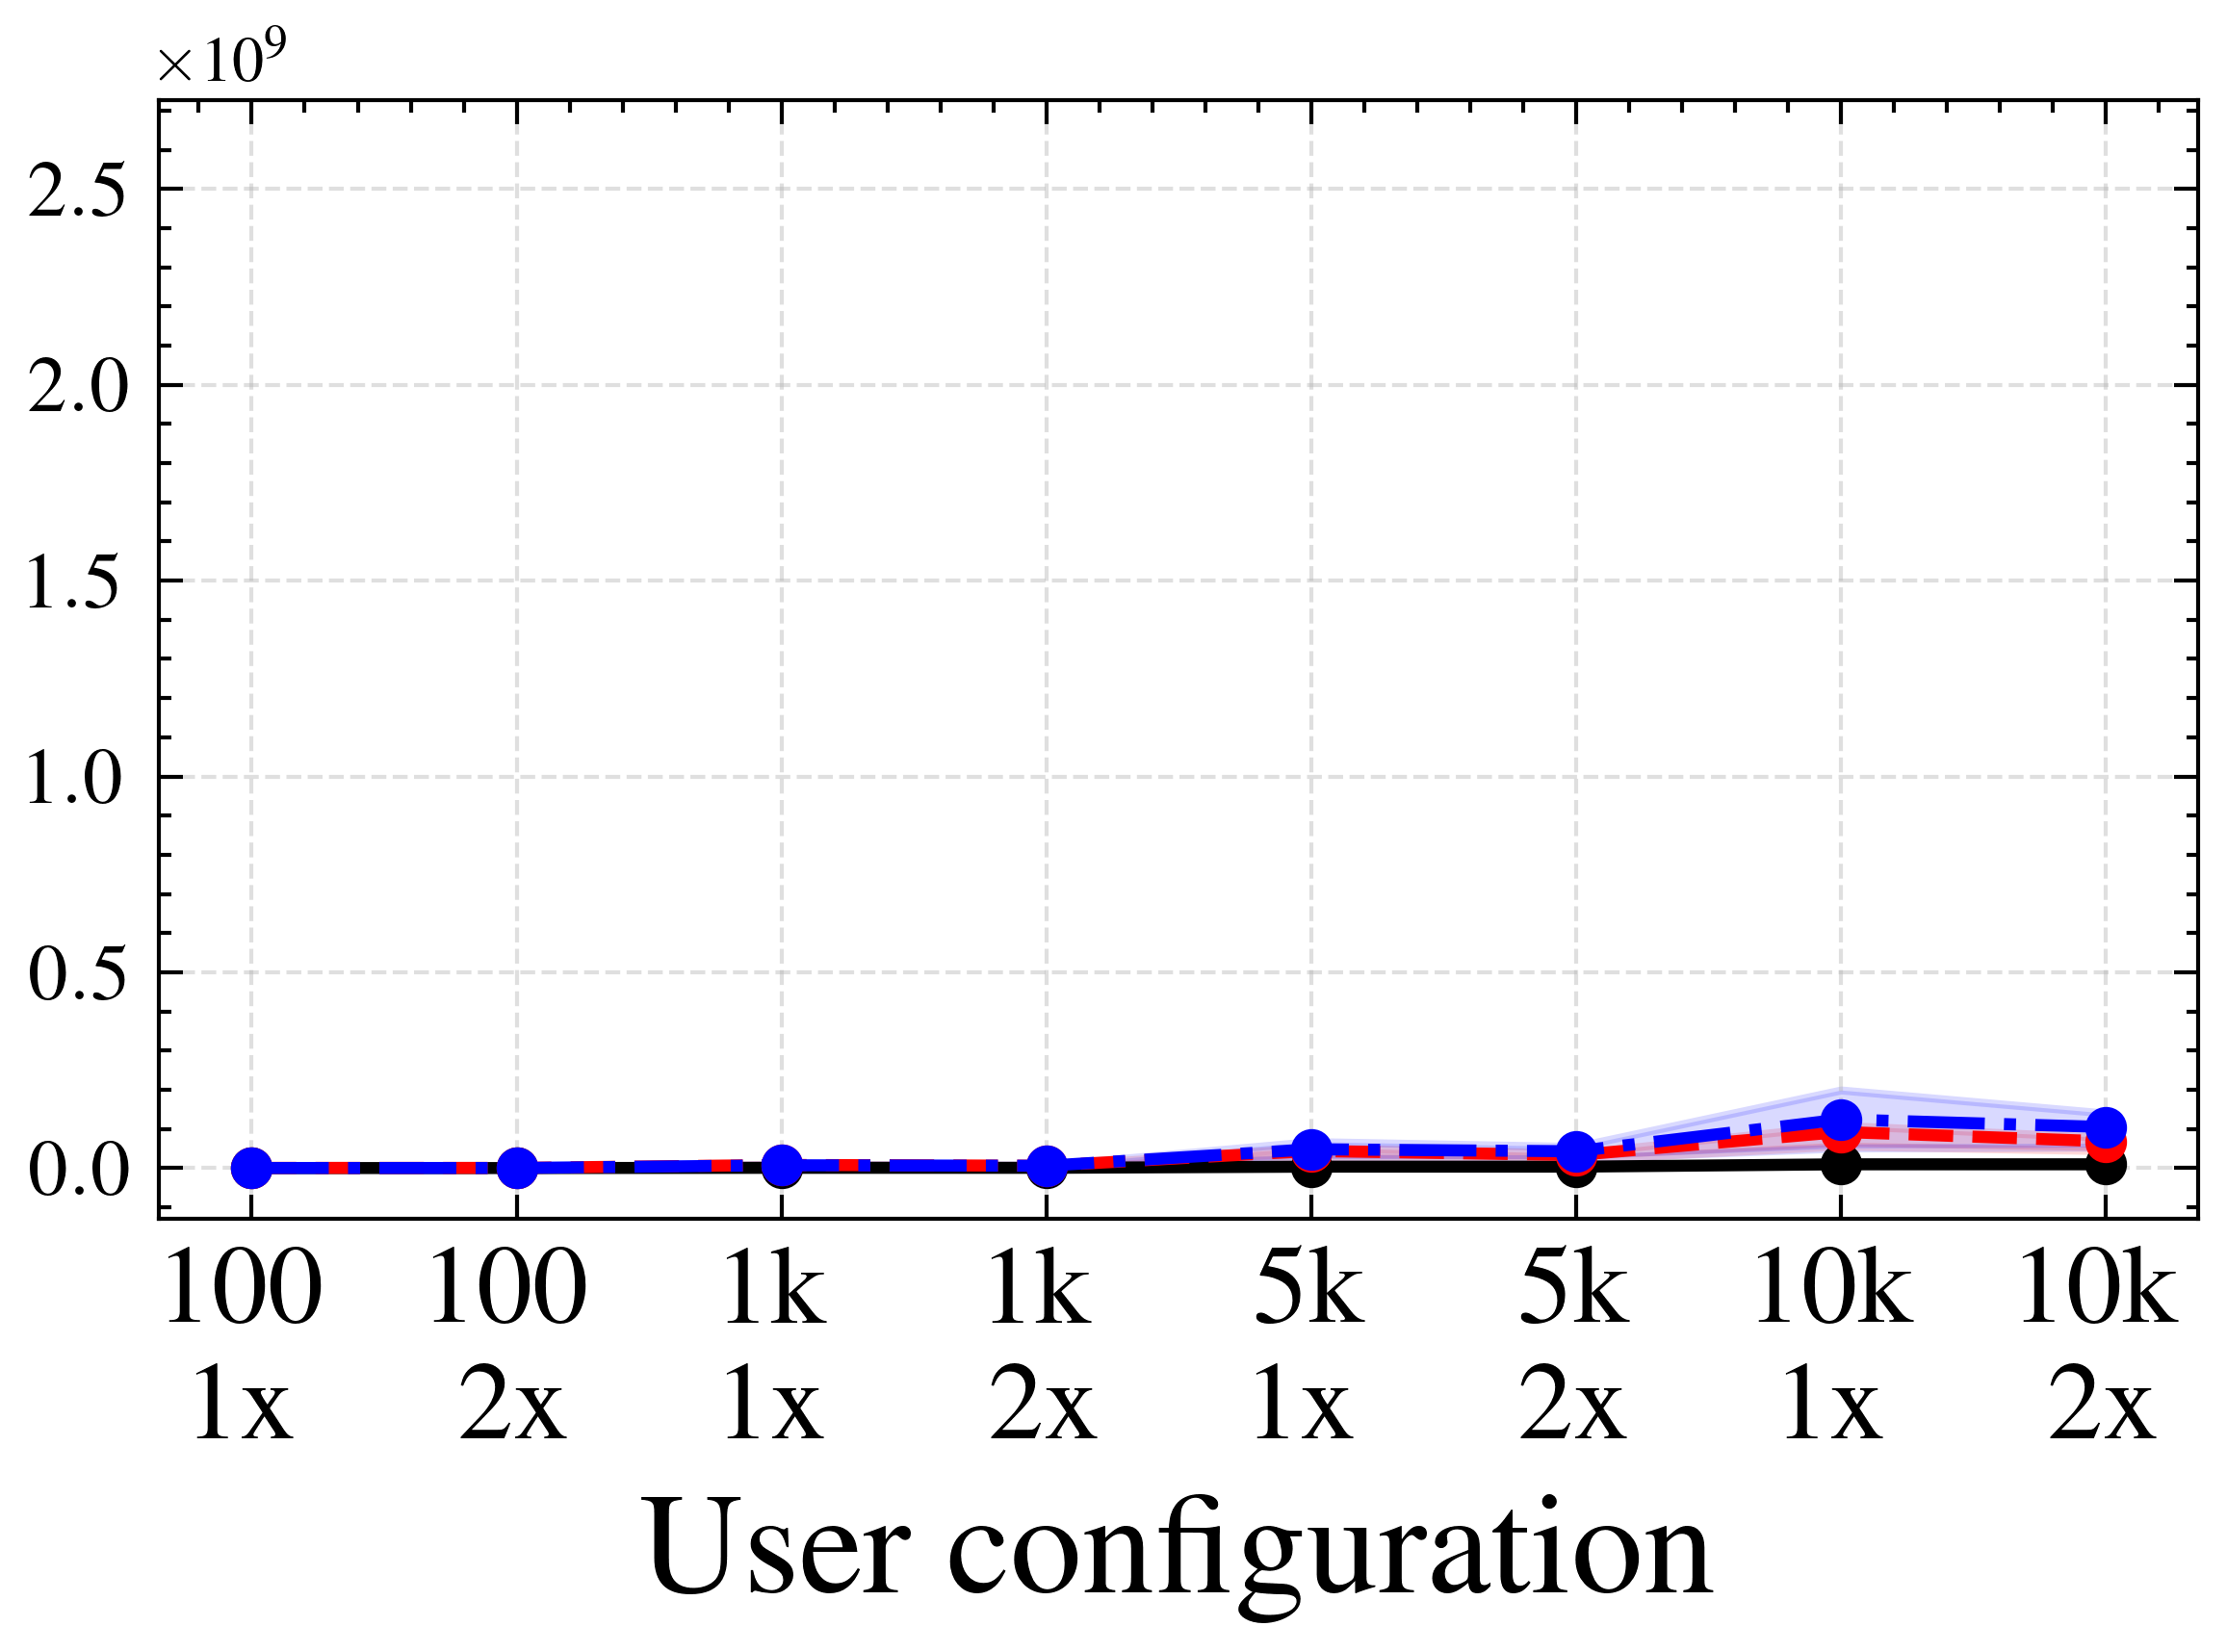

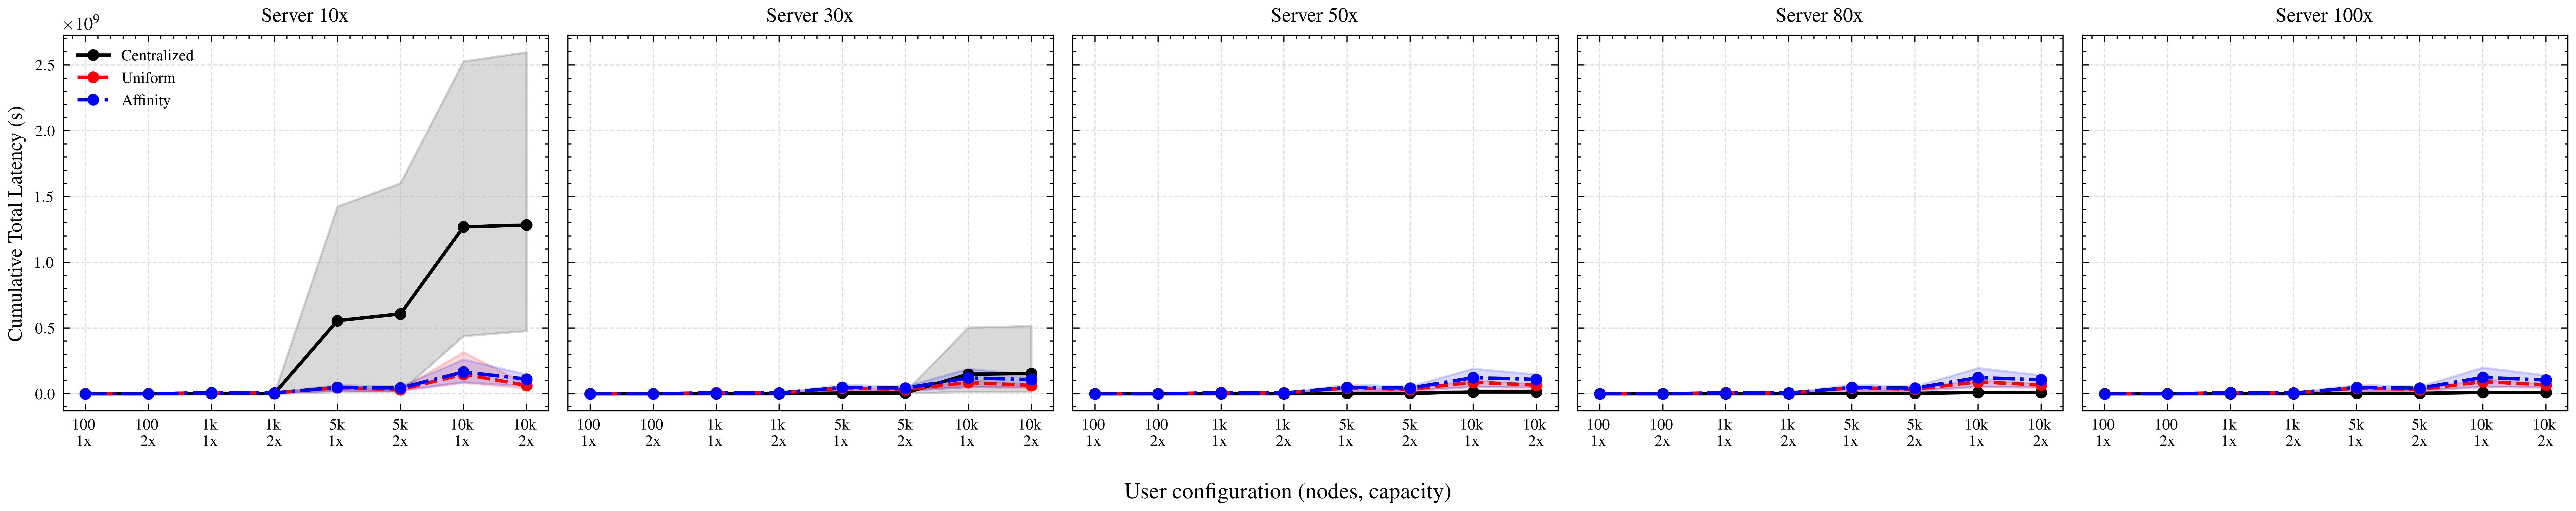

In [52]:
# Shared y-limits for cum_total individual figures
_finite = [v for vals in _all_vals.values() for v in vals[1] if not np.isnan(v)]
_y_pad  = (max(_finite) - min(_finite)) * 0.05
_ylim_cum_total = (min(_finite) - _y_pad, max(_finite) + _y_pad)

# Separate figures: cumulative total latency, shaded bands across request types
for i, server_mult in enumerate(server_mults):
    fig, ax = plt.subplots(figsize=(4, 3))

    for policy, policy_label in zip(POLICIES, POLICY_LABELS):
        color = POLICY_COLORS[policy]
        ls    = POLICY_LINESTYLES[policy]

        task_cum  = np.array([_all_vals[(server_mult, t, policy)][1] for t in range(n_tasks)])
        mean_vals = np.nanmean(task_cum, axis=0)
        min_vals  = np.nanmin(task_cum, axis=0)
        max_vals  = np.nanmax(task_cum, axis=0)

        ax.plot(x_pos, mean_vals, color=color, linestyle=ls, marker="o",
                markersize=4, markeredgewidth=1.2, linewidth=1.5, label=policy_label)
        ax.fill_between(x_pos, min_vals, max_vals, color=color, alpha=0.15)

    ax.set_ylim(_ylim_cum_total)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, fontsize=14)
    ax.tick_params(axis="y", labelsize=10)
    ax.tick_params(axis="x", which="minor", bottom=False)
    ax.set_xlabel("User configuration", fontsize=18)
    ax.grid(True, linestyle="--", alpha=0.4)

    if i == 0:
        ax.set_ylabel("Cumulative Total Latency (s)", fontsize=18)
        ax.legend(fontsize=10.5, loc="upper left", ncol=1)

    fname = f"cum_total_latency_server_{server_mult}x.pdf"
    plt.tight_layout()
    plt.savefig(os.path.join(figures_dir, fname), bbox_inches="tight")
    print(f"Figure {i + 1} — server {server_mult}x  →  {fname}")
    plt.show()

# 1×5 grid: cumulative total latency
fig, axes = plt.subplots(
    1, len(server_mults),
    figsize=(3.2 * len(server_mults), 3.2),
    sharex=True,
    sharey=True
)

for col, server_mult in enumerate(server_mults):
    ax = axes[col]

    for policy, policy_label in zip(POLICIES, POLICY_LABELS):
        color = POLICY_COLORS[policy]
        ls    = POLICY_LINESTYLES[policy]

        task_cum  = np.array([_all_vals[(server_mult, t, policy)][1] for t in range(n_tasks)])
        mean_vals = np.nanmean(task_cum, axis=0)
        min_vals  = np.nanmin(task_cum, axis=0)
        max_vals  = np.nanmax(task_cum, axis=0)

        ax.plot(x_pos, mean_vals, color=color, linestyle=ls,
                marker="o", markersize=4, markeredgewidth=1.2,
                linewidth=1.5, label=policy_label)
        ax.fill_between(x_pos, min_vals, max_vals, color=color, alpha=0.15)

    ax.set_title(f"Server {server_mult}x", fontsize=9, fontweight="bold")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, fontsize=7)
    ax.tick_params(axis="y", labelsize=7)
    ax.tick_params(axis="x", which="minor", bottom=False)
    ax.grid(True, linestyle="--", alpha=0.4)

axes[0].set_ylabel("Cumulative Total Latency (s)", fontsize=9)
axes[0].legend(fontsize=7, loc="upper left")

fig.supxlabel("User configuration (nodes, capacity)", fontsize=10, y=0.01)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "cum_total_latency_grid.pdf"), bbox_inches="tight")
plt.show()

Figure 1 — server 10x  →  cum_mean_latency_server_10x.pdf


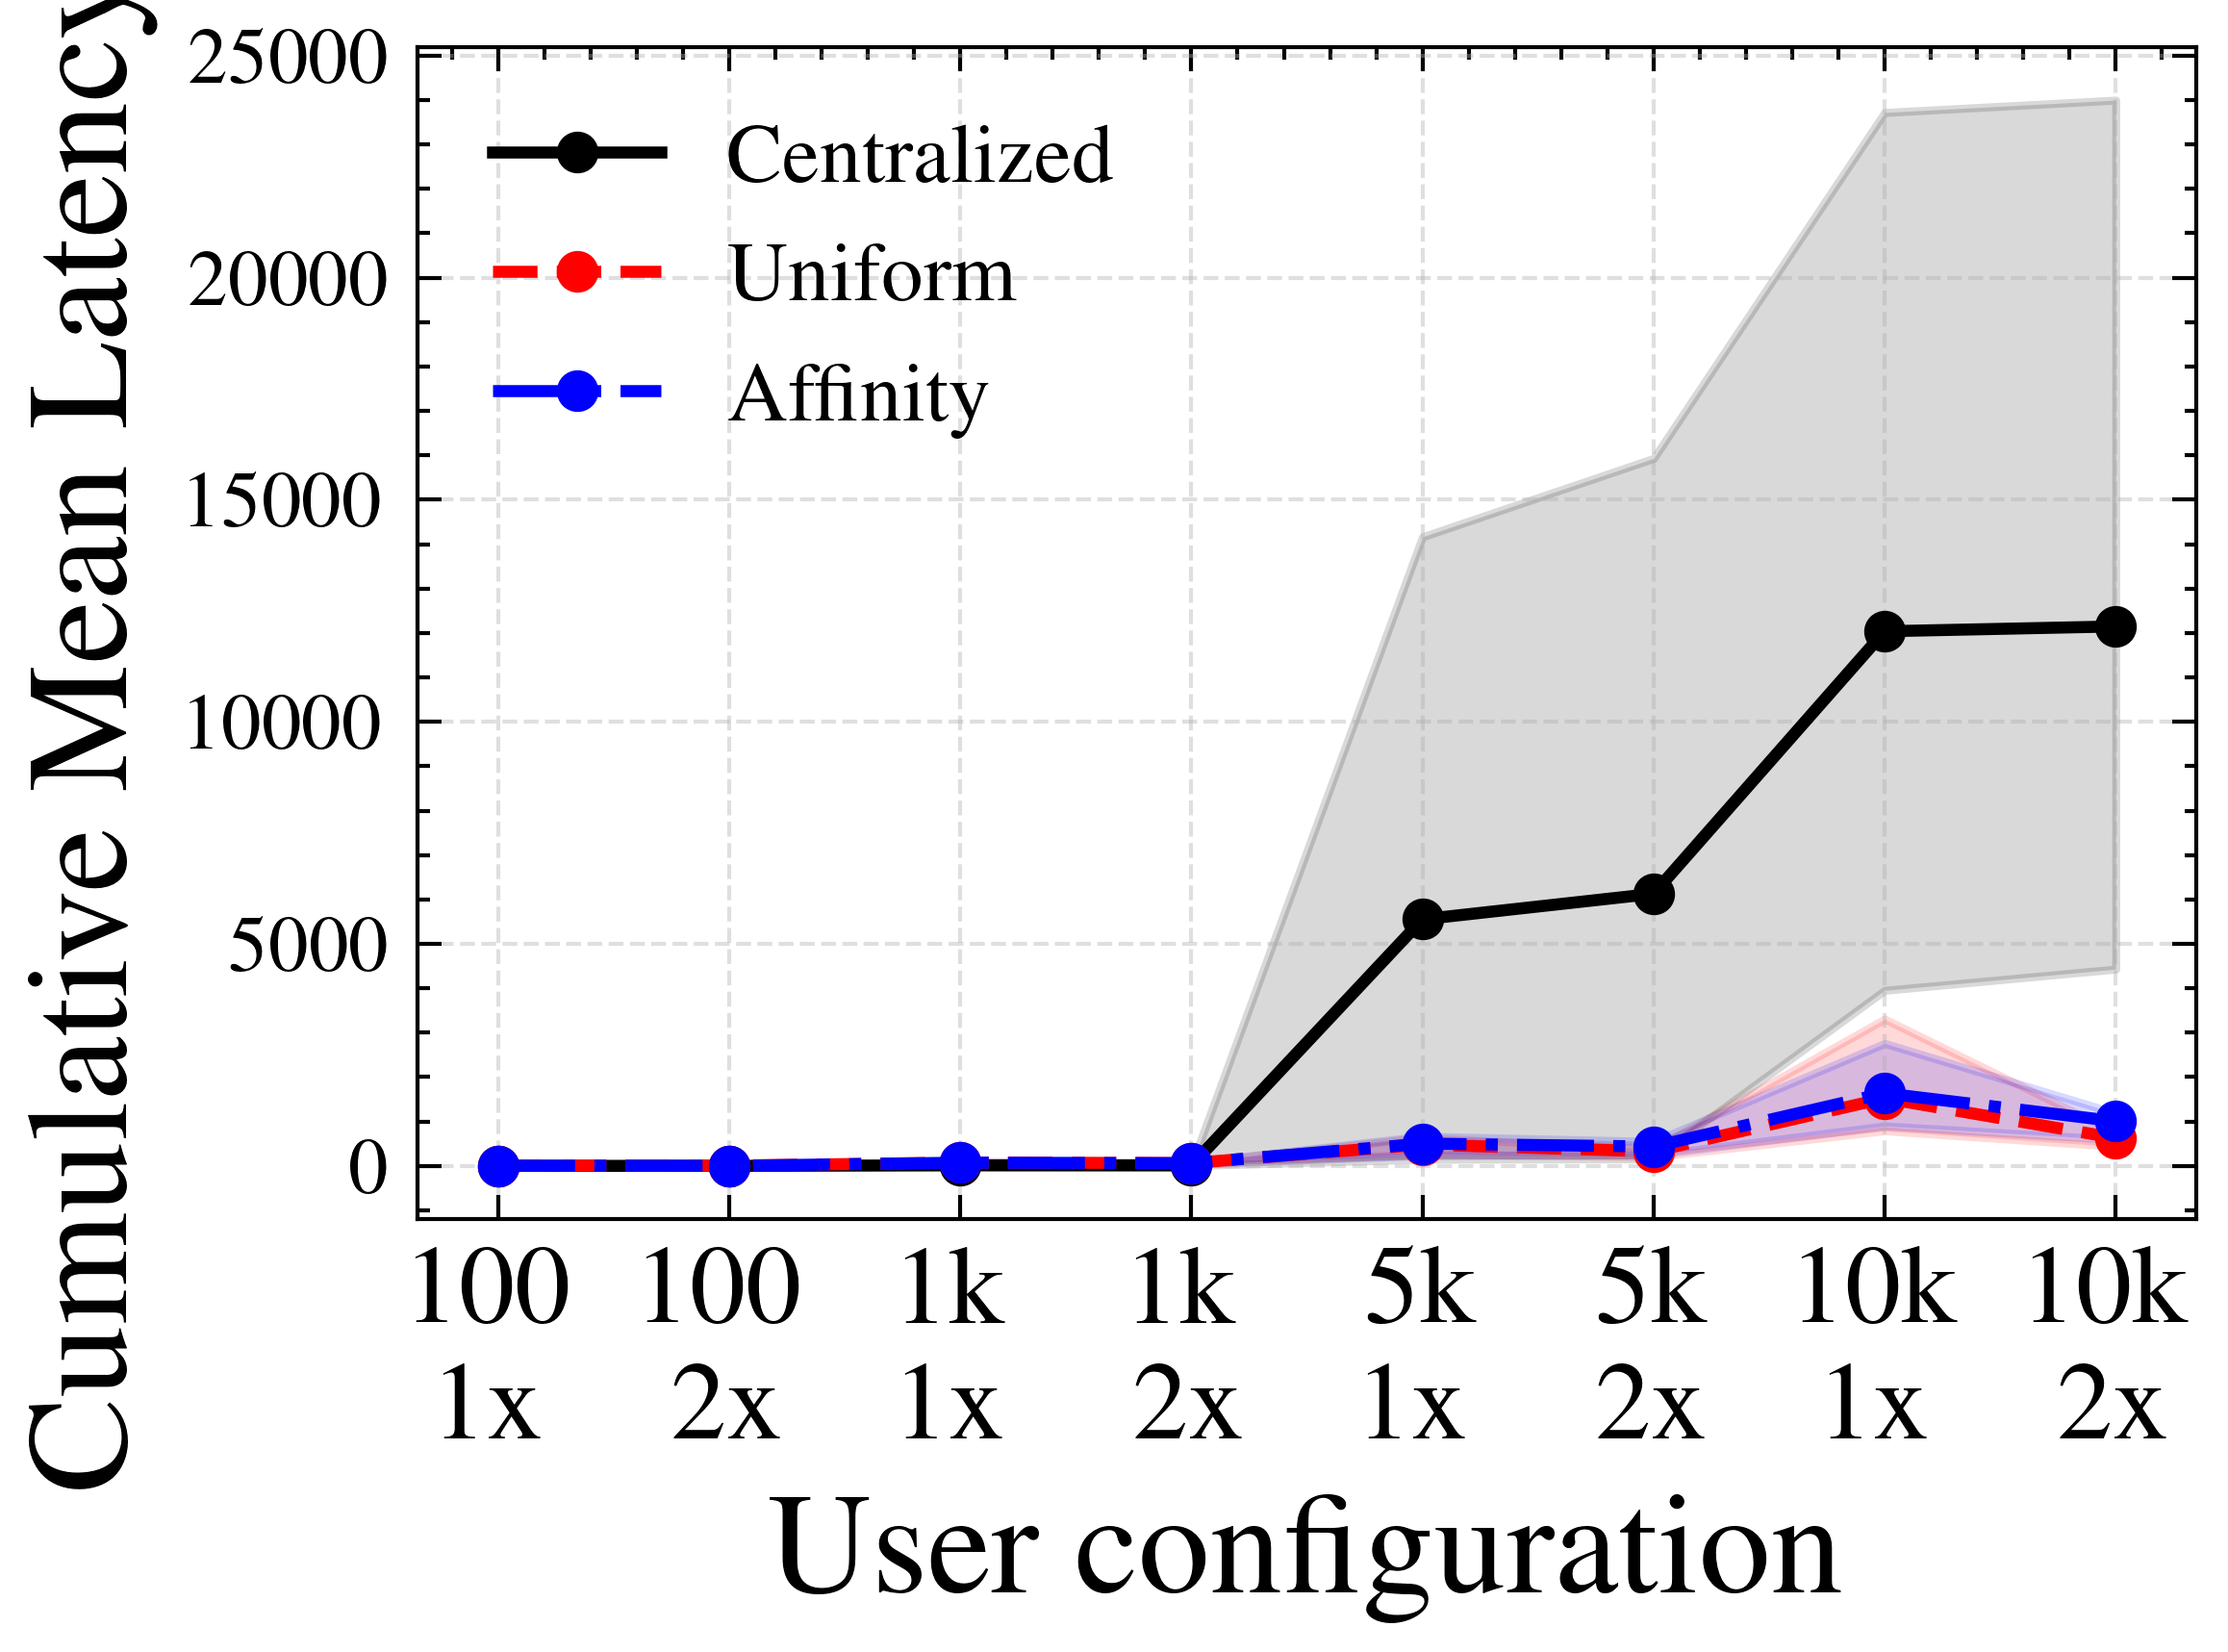

Figure 2 — server 30x  →  cum_mean_latency_server_30x.pdf


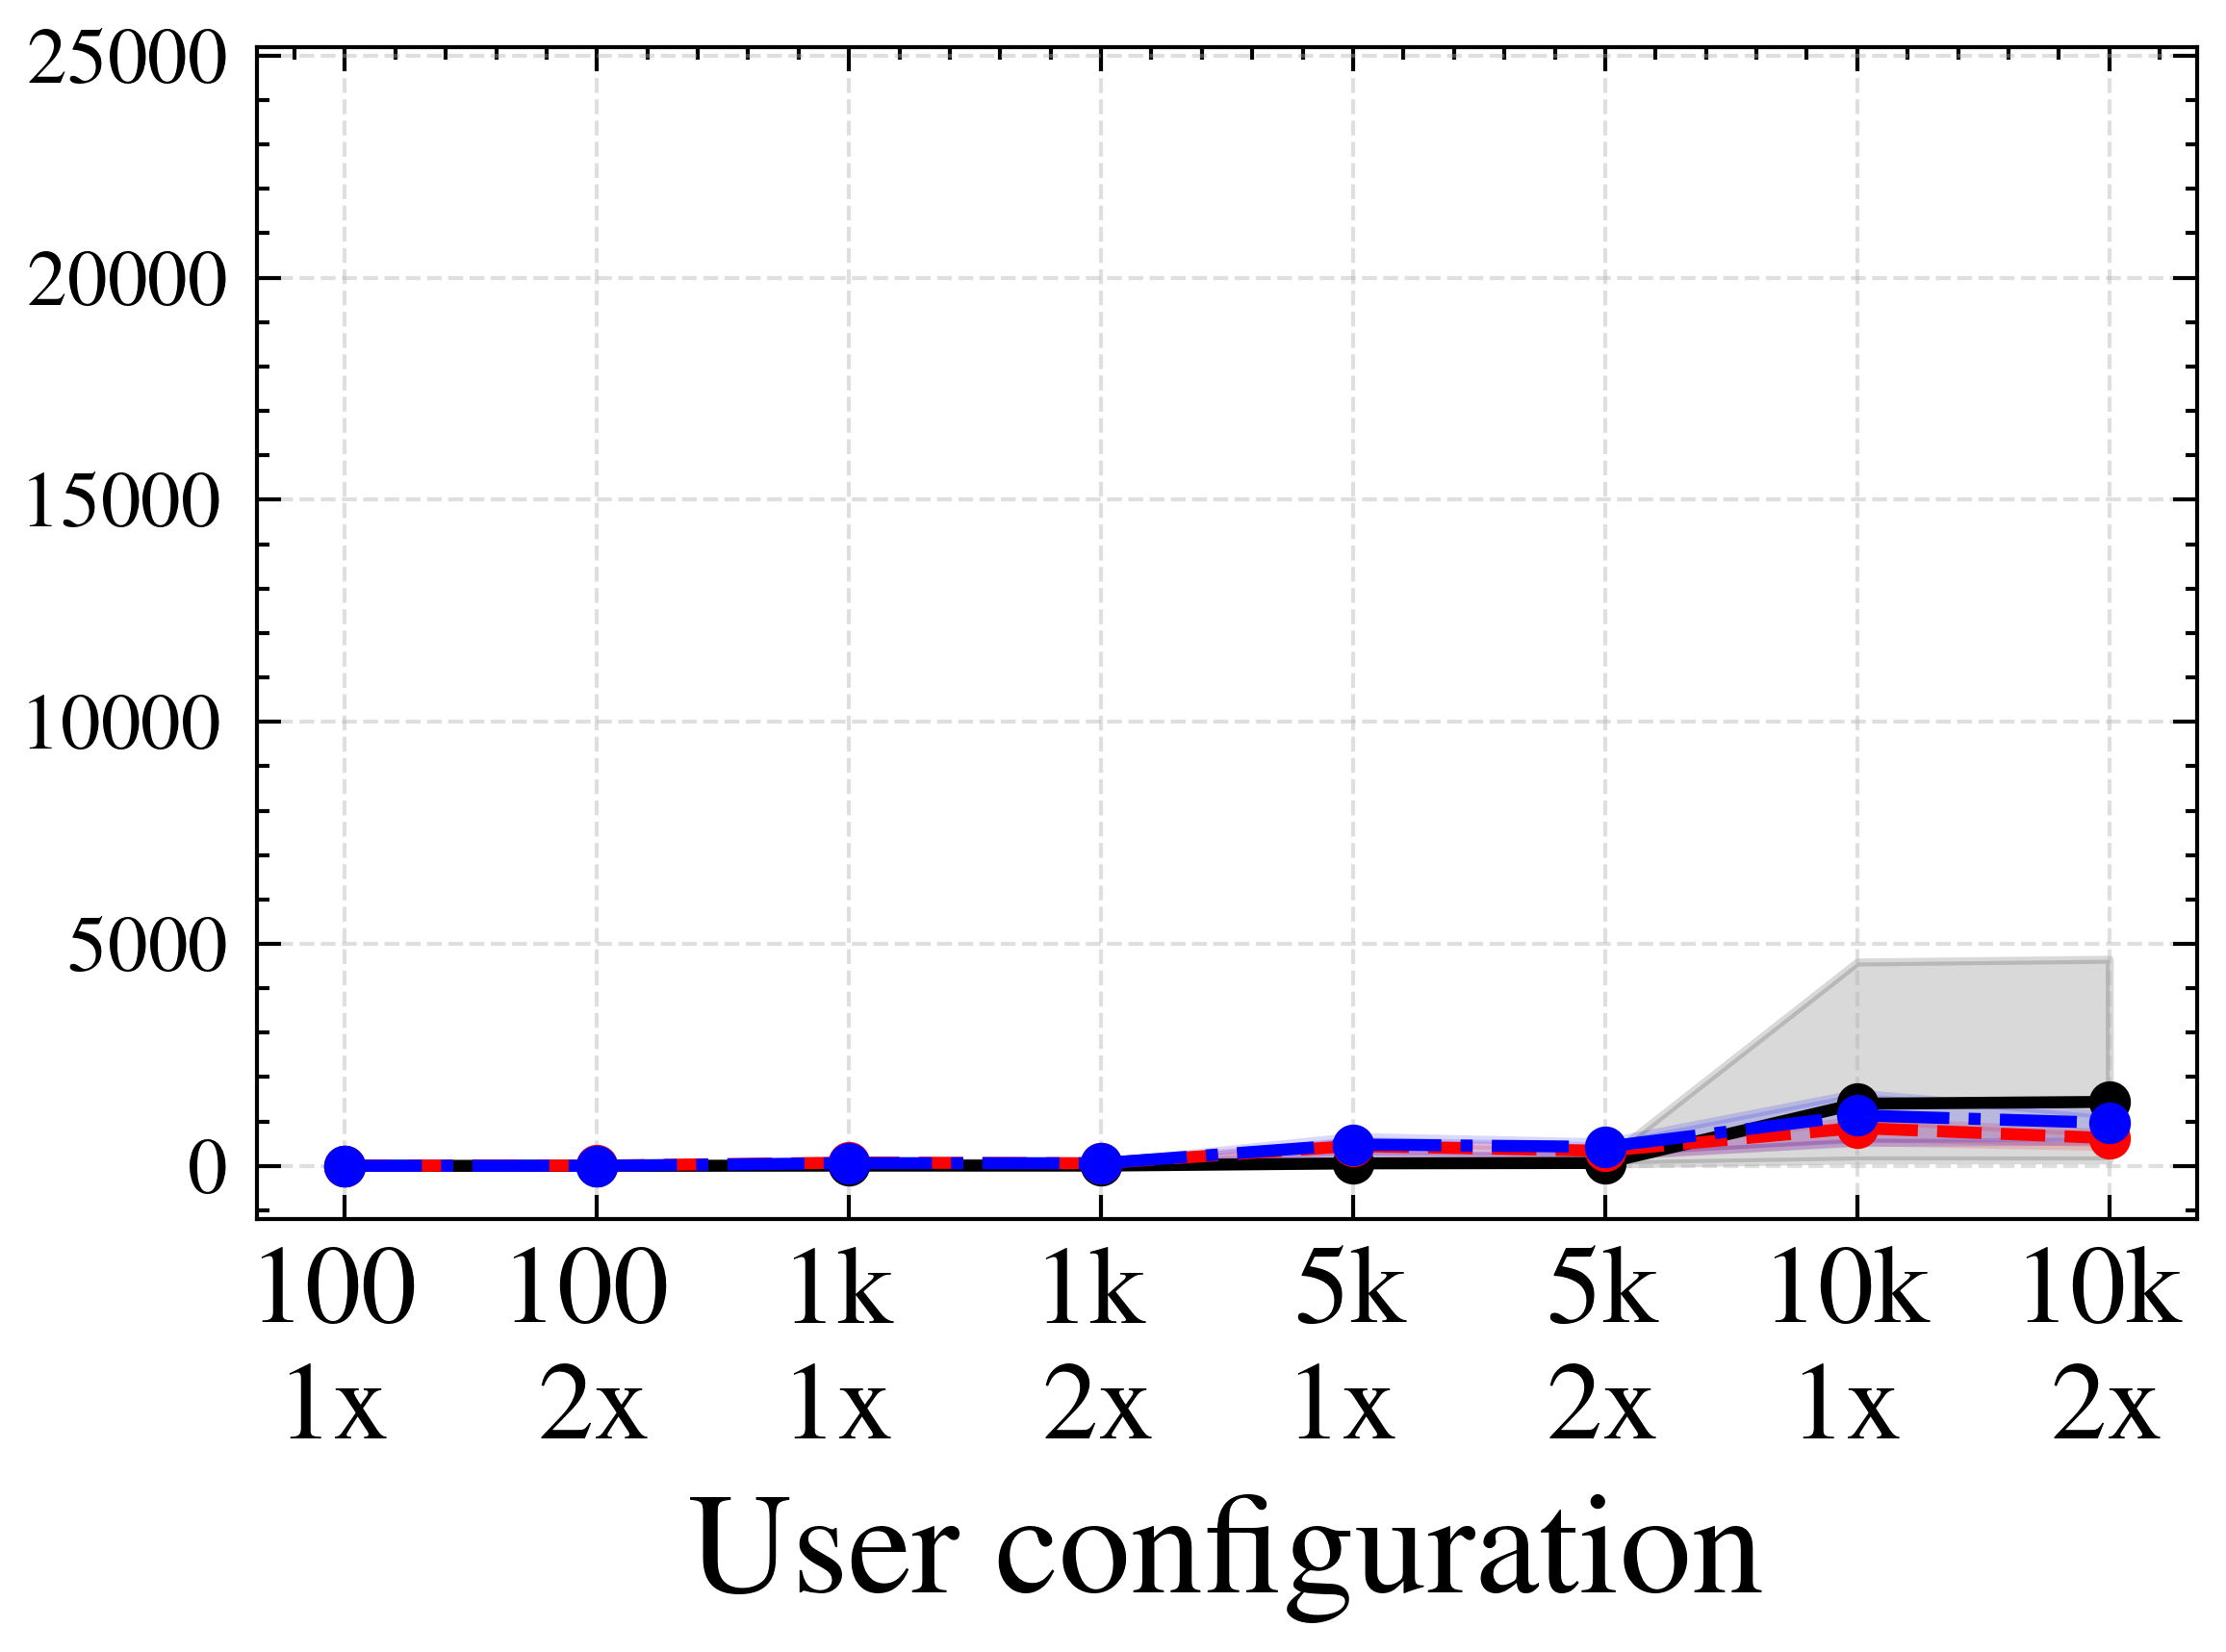

Figure 3 — server 50x  →  cum_mean_latency_server_50x.pdf


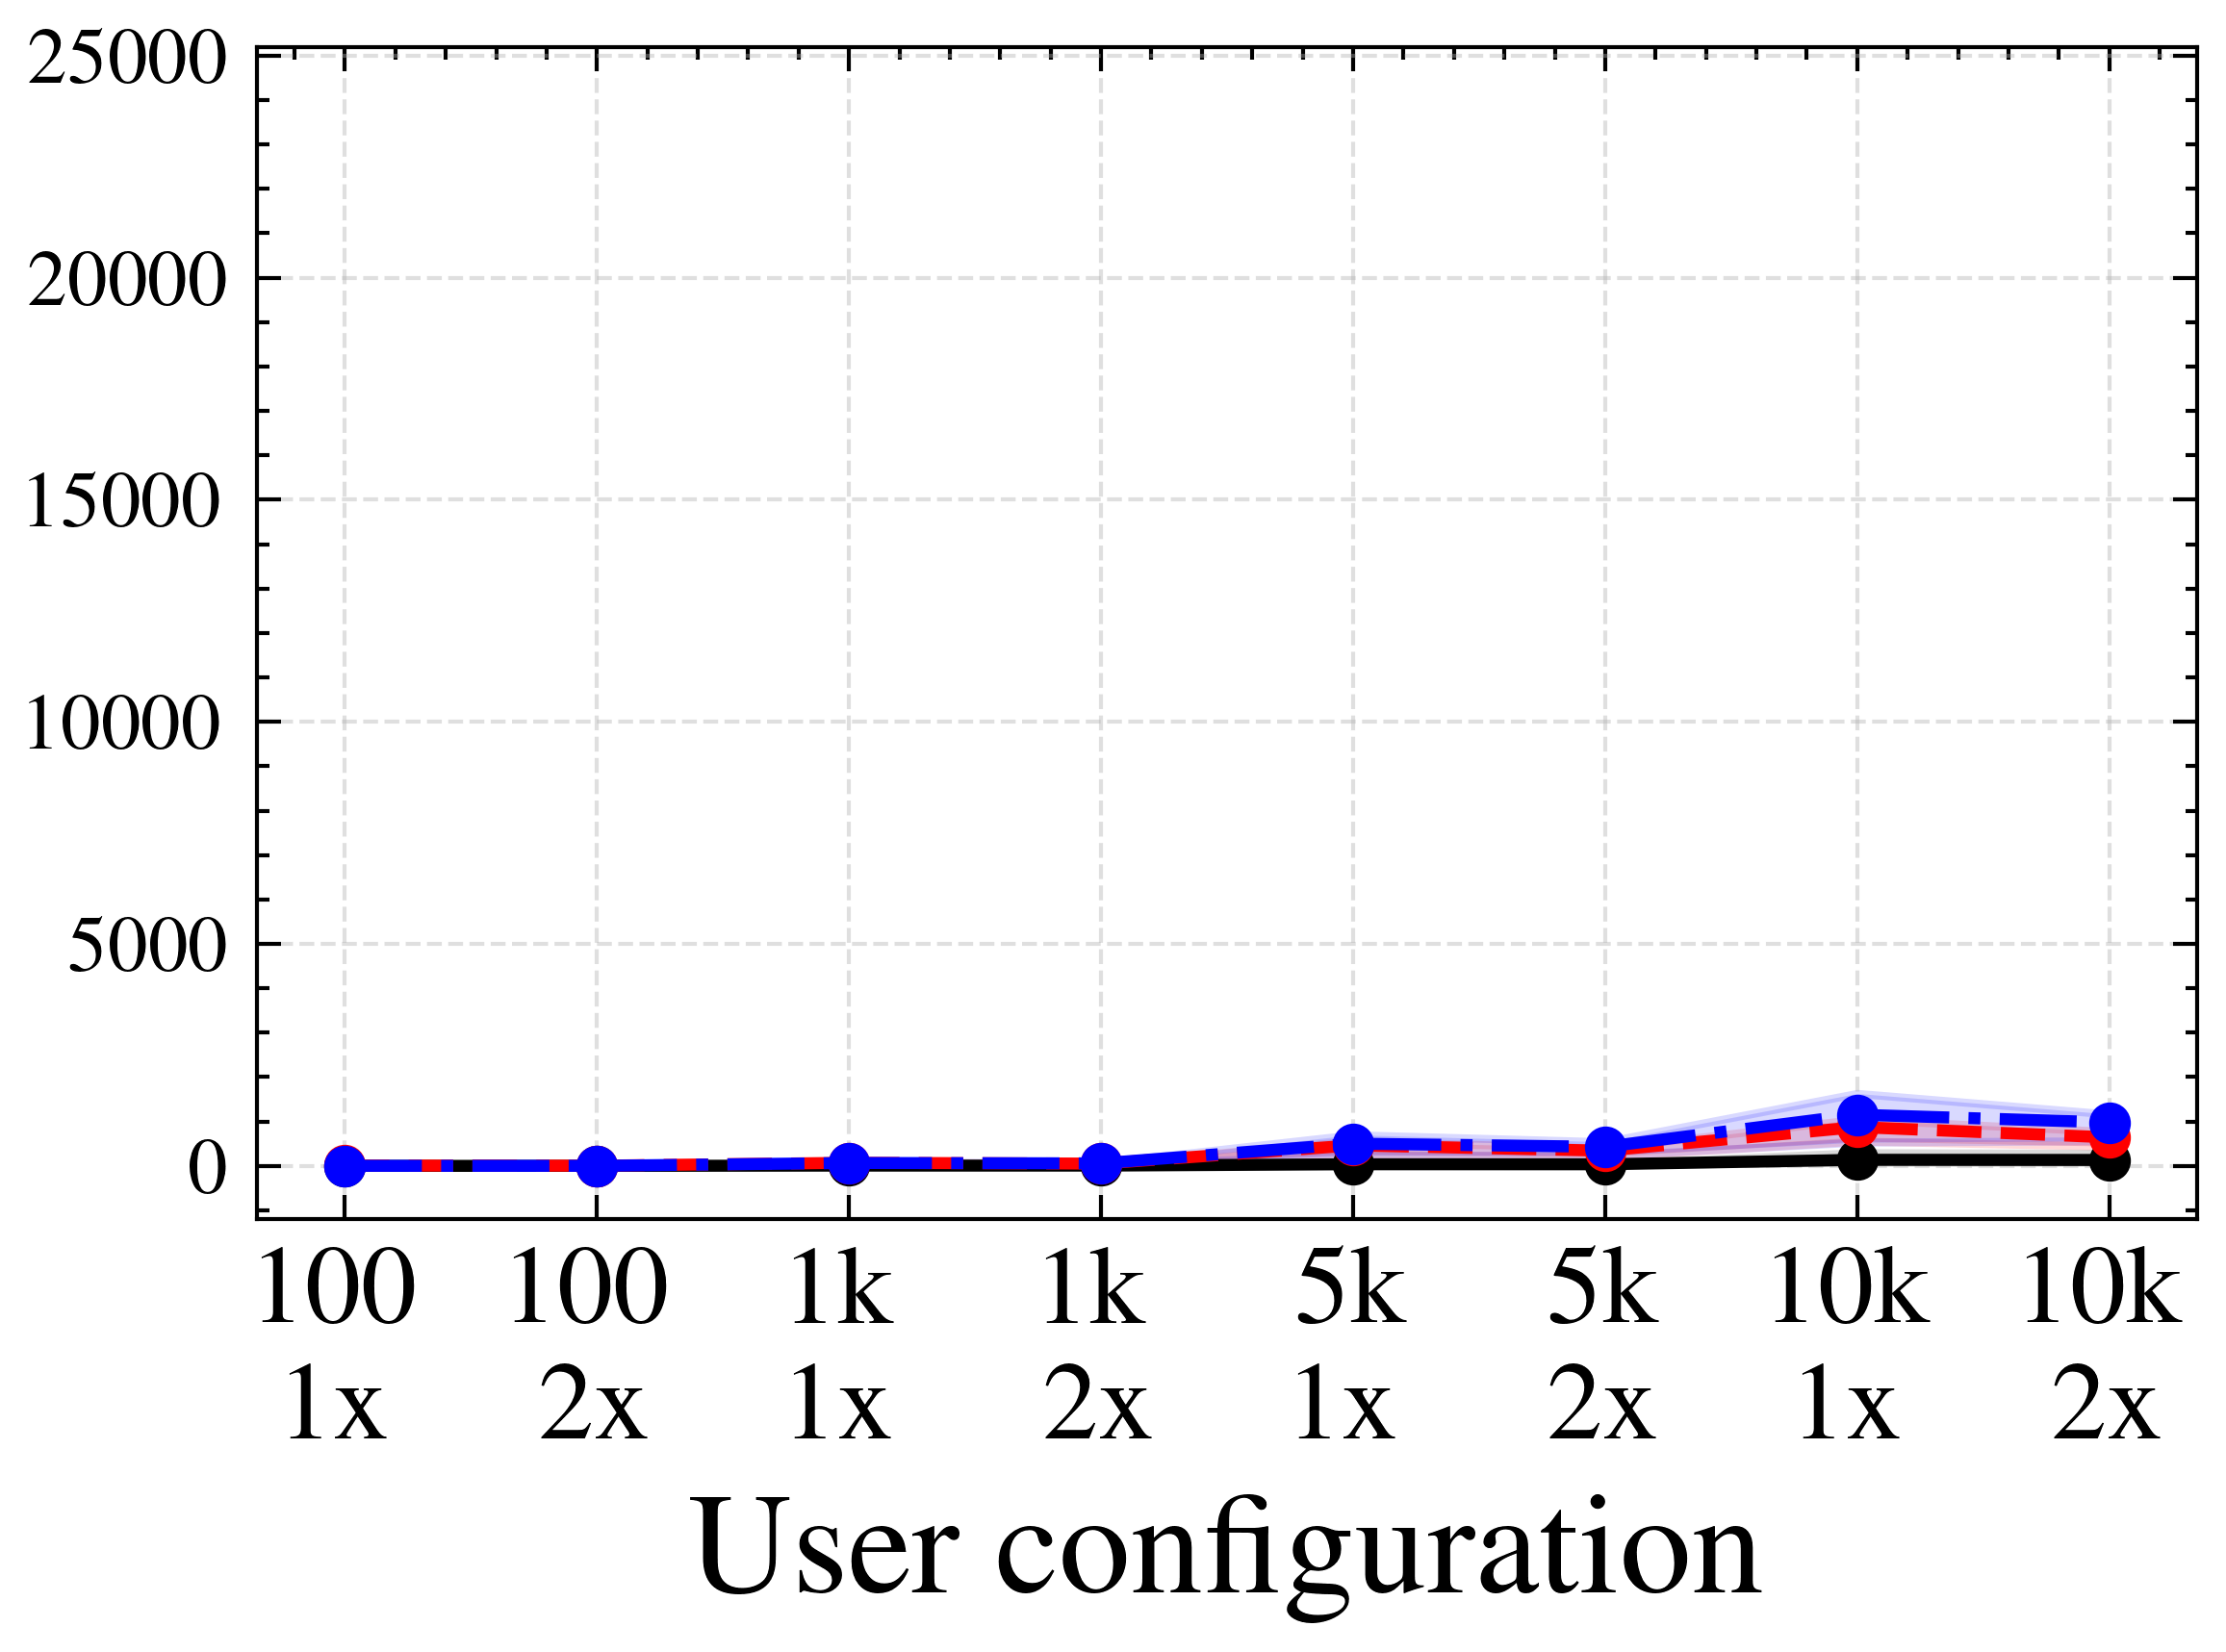

Figure 4 — server 80x  →  cum_mean_latency_server_80x.pdf


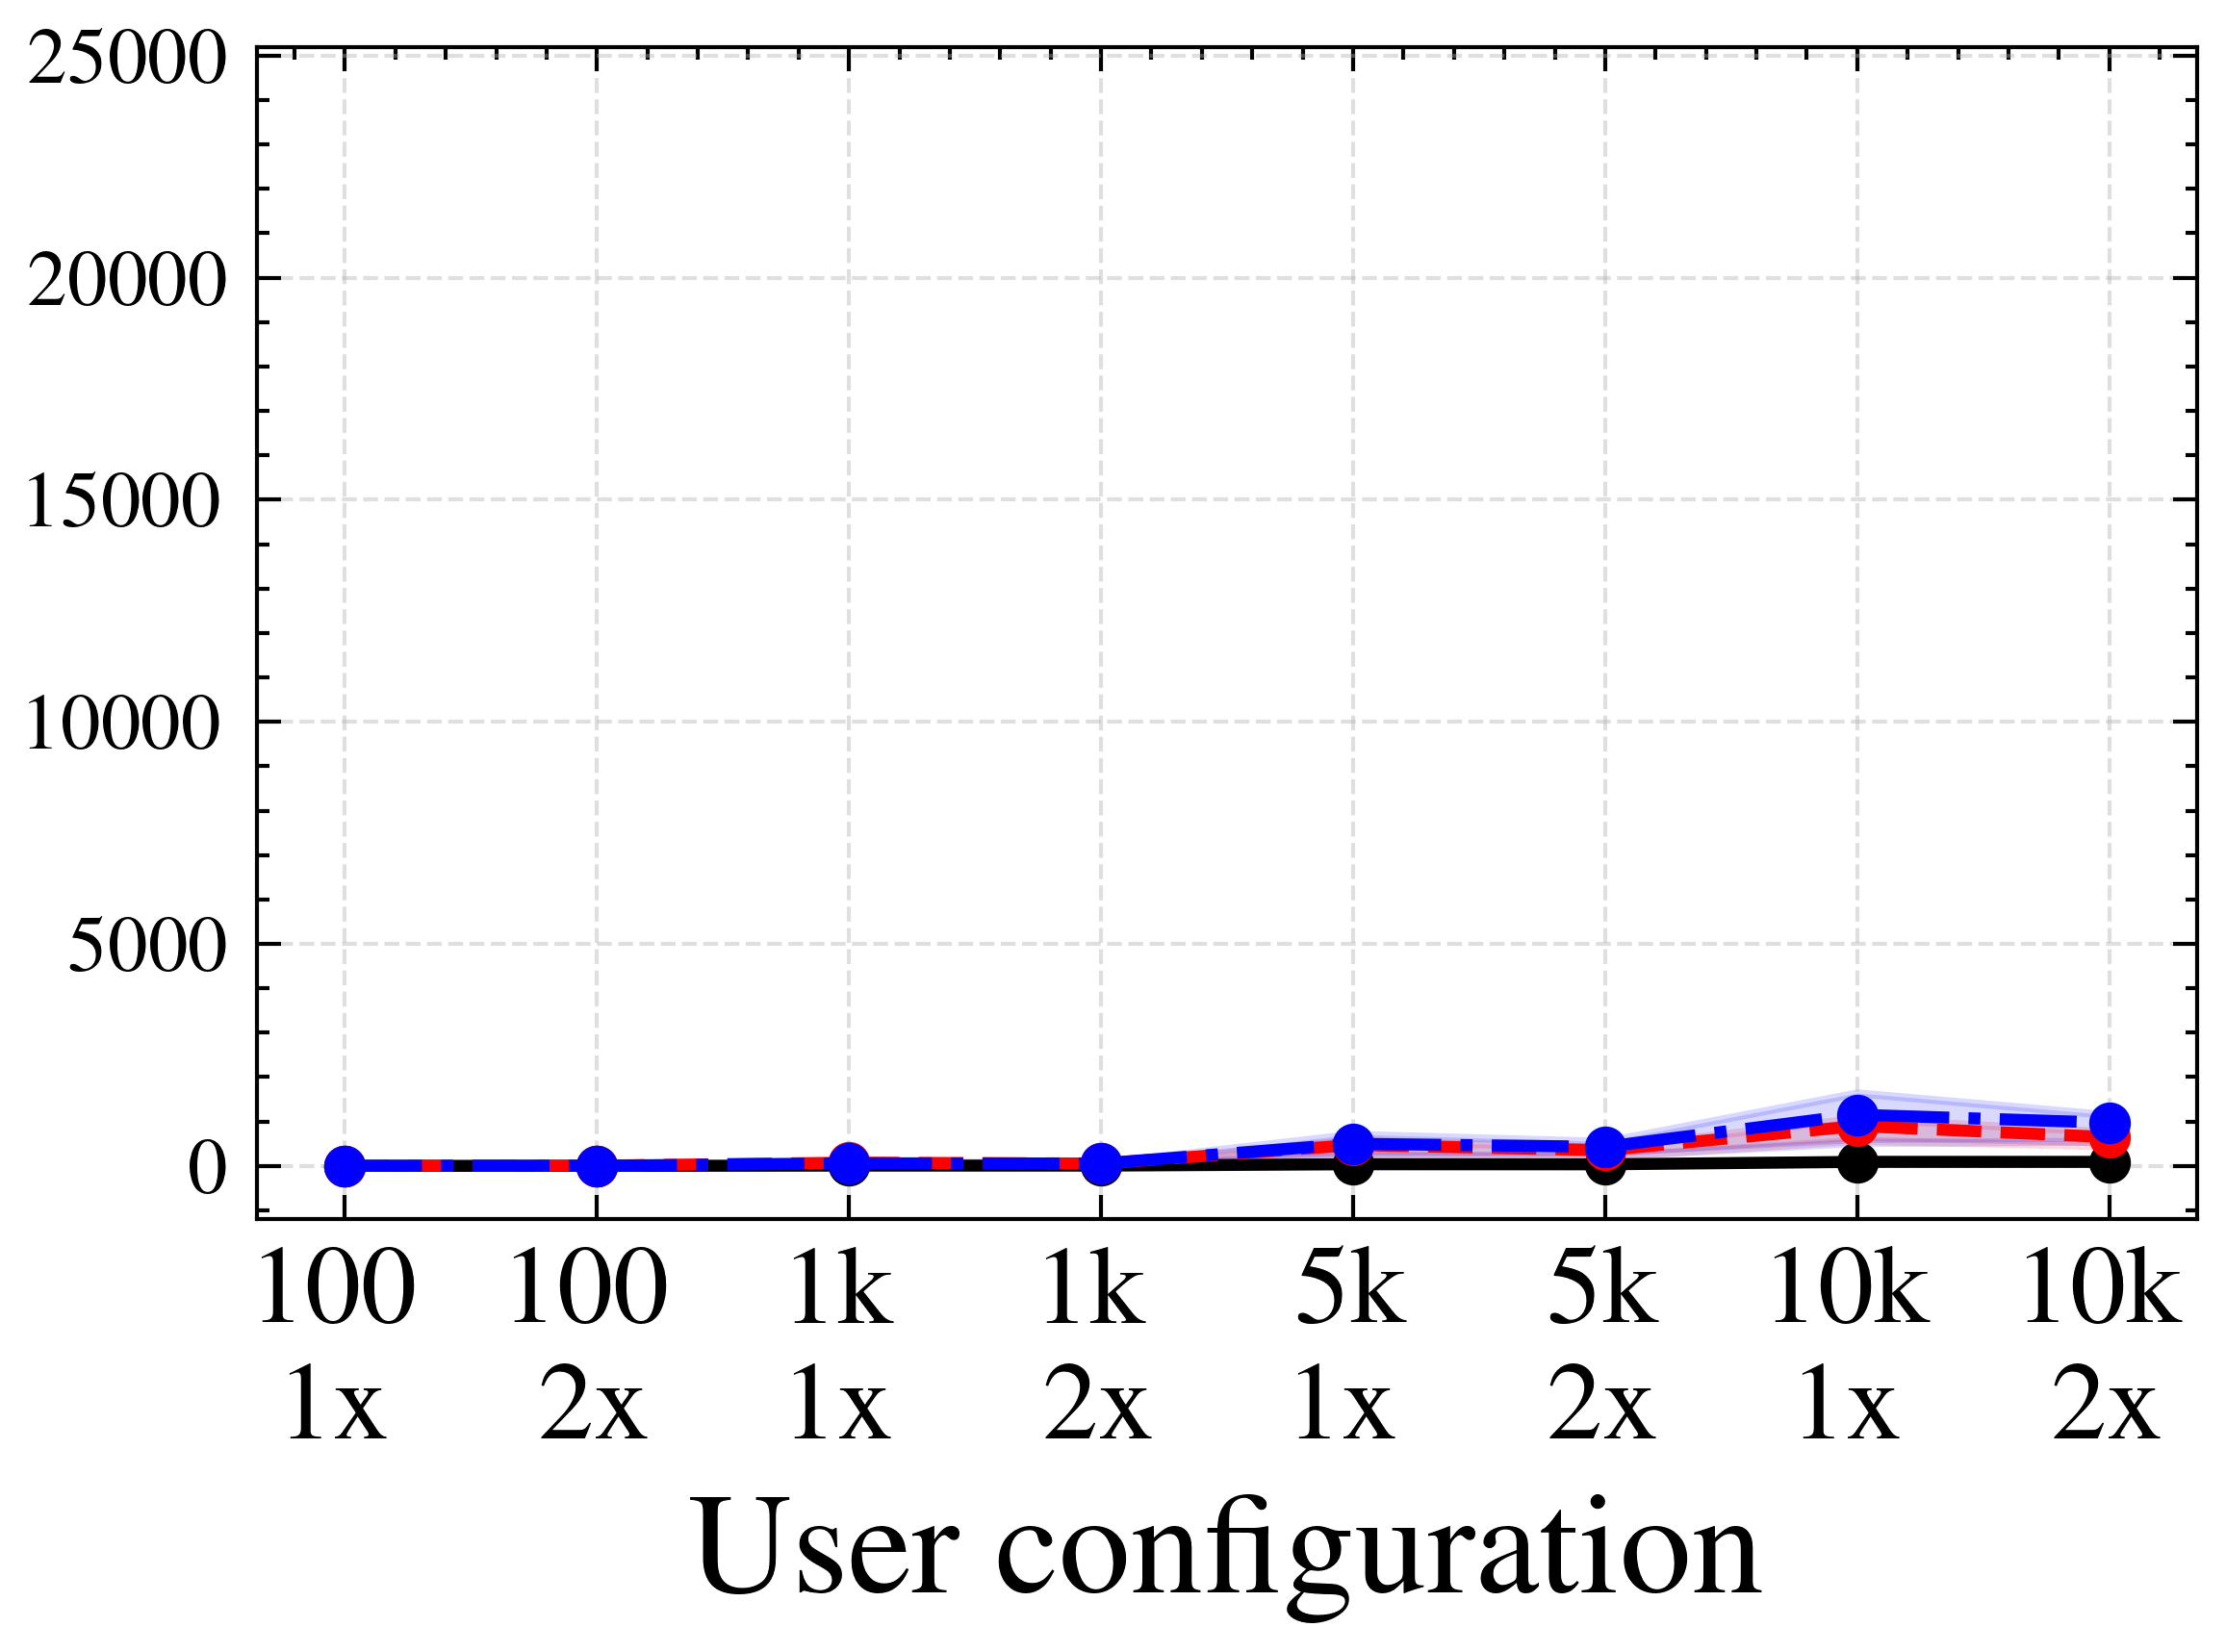

Figure 5 — server 100x  →  cum_mean_latency_server_100x.pdf


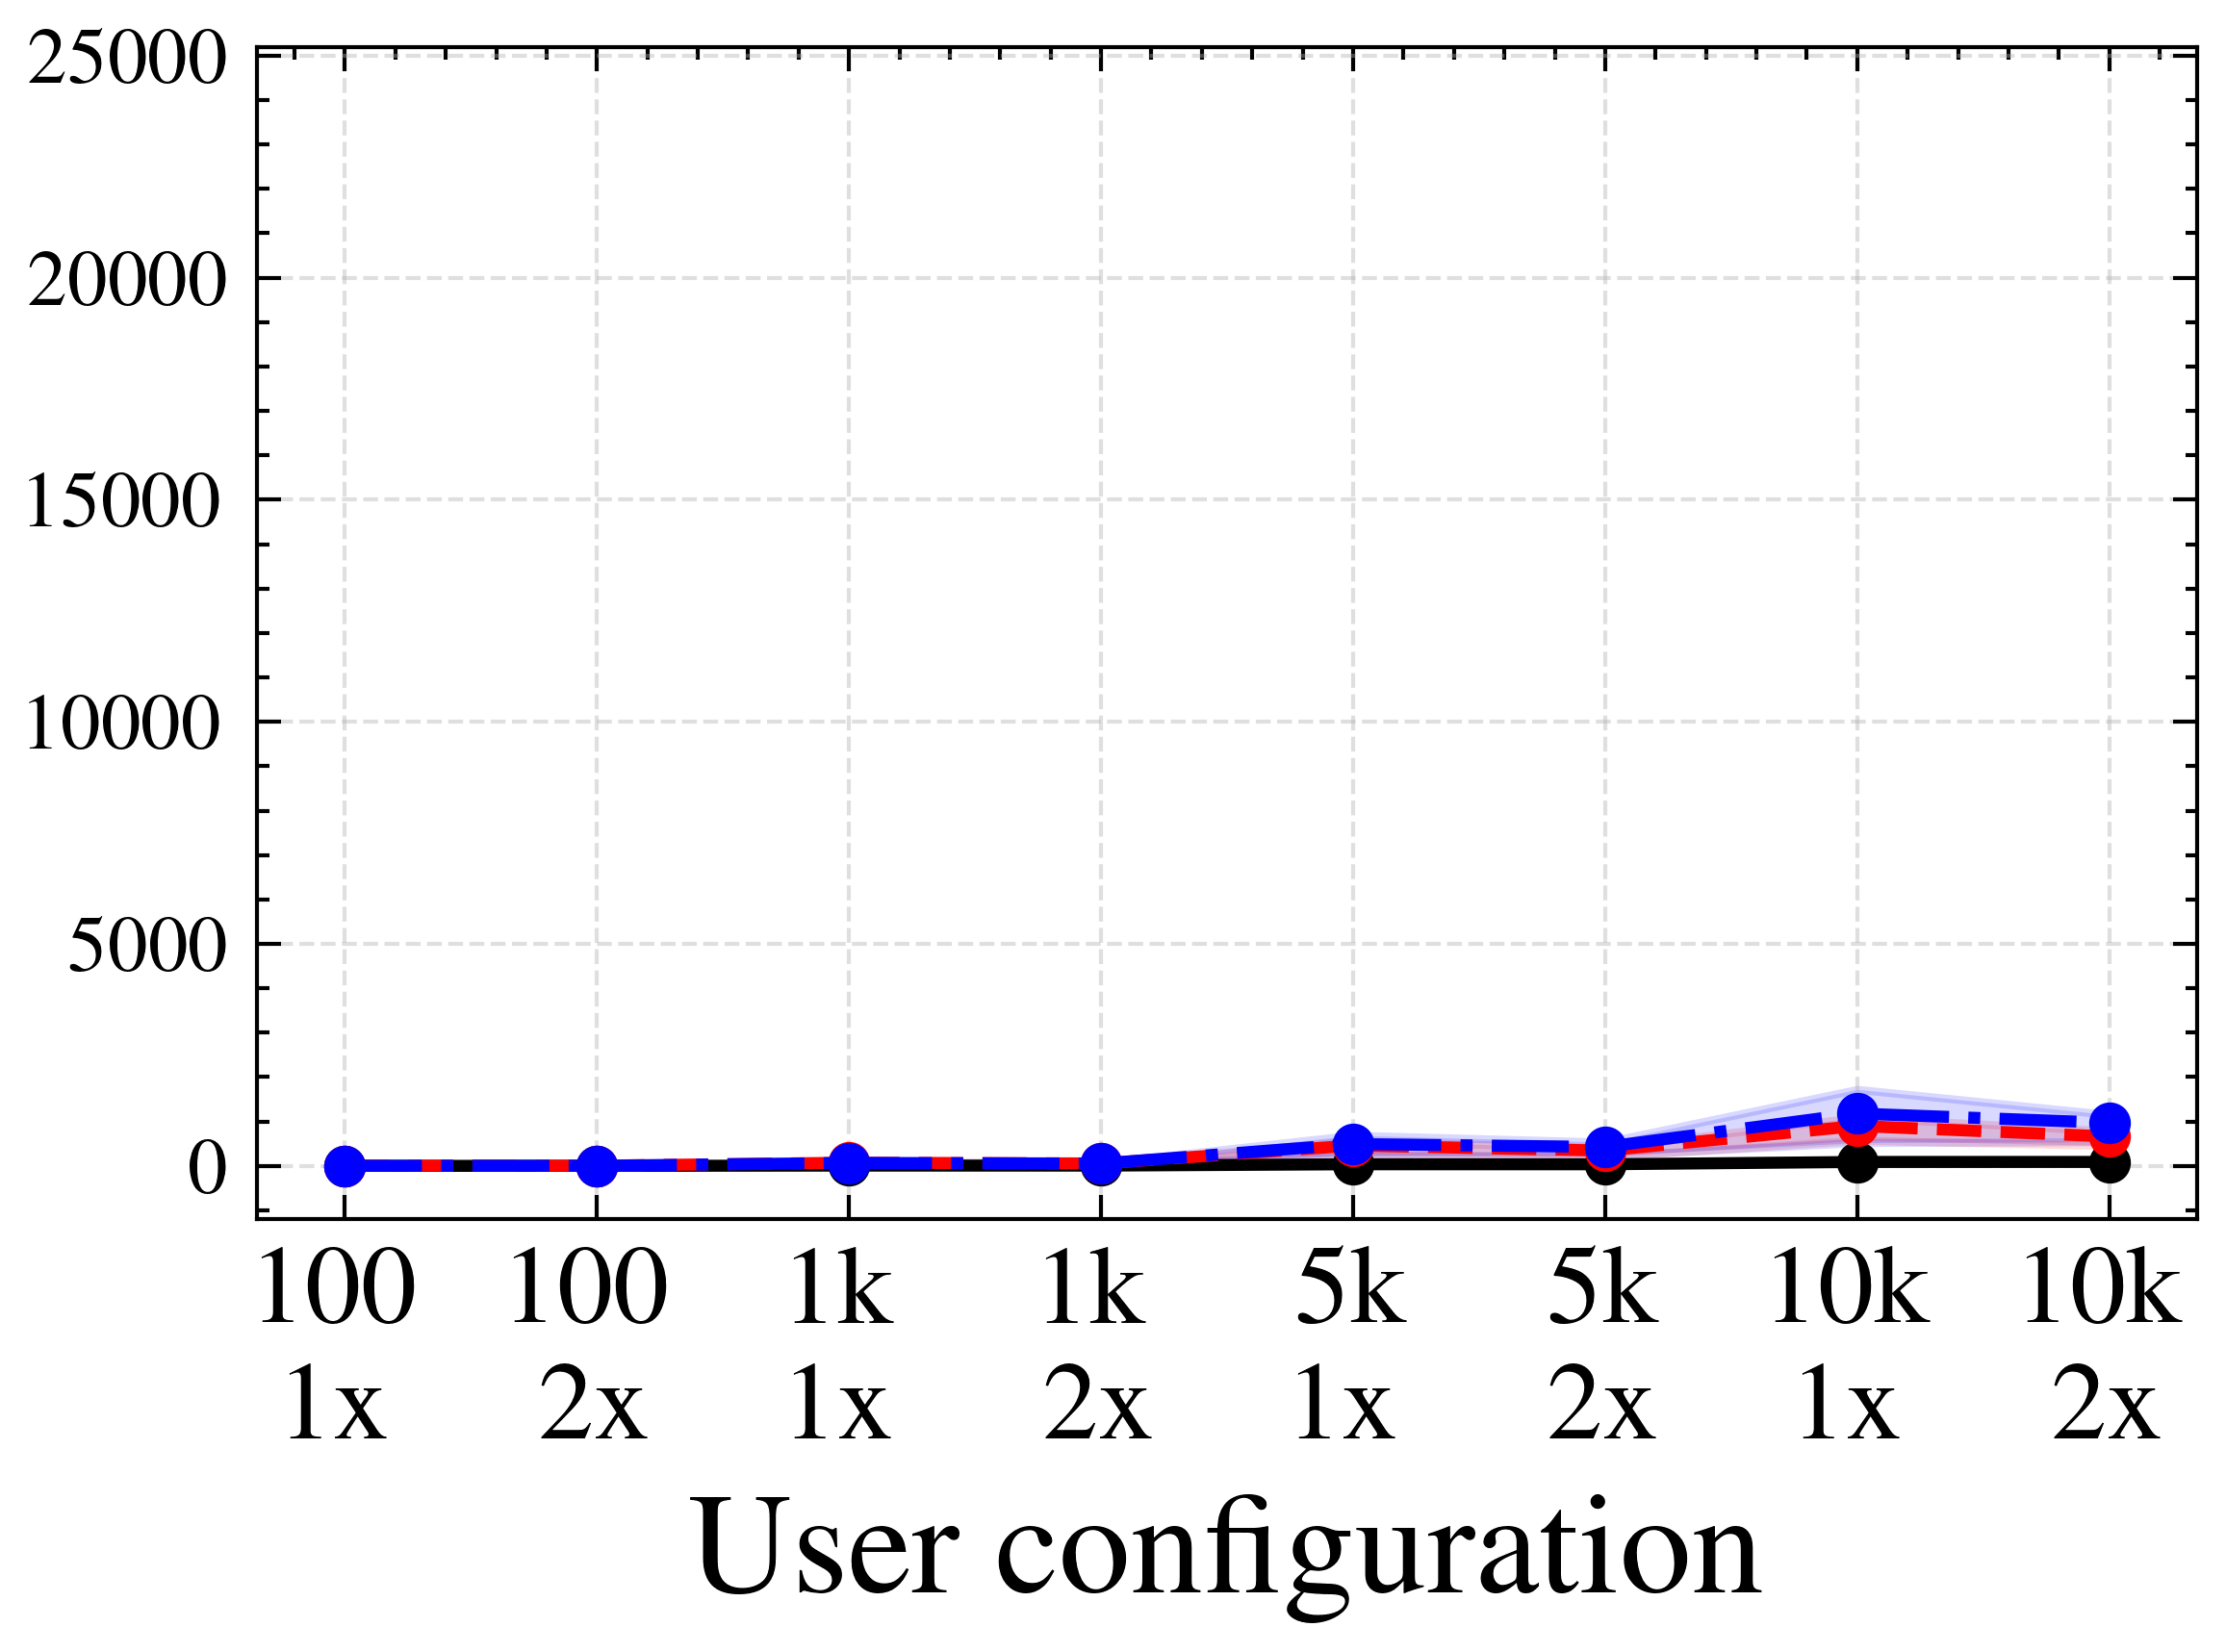

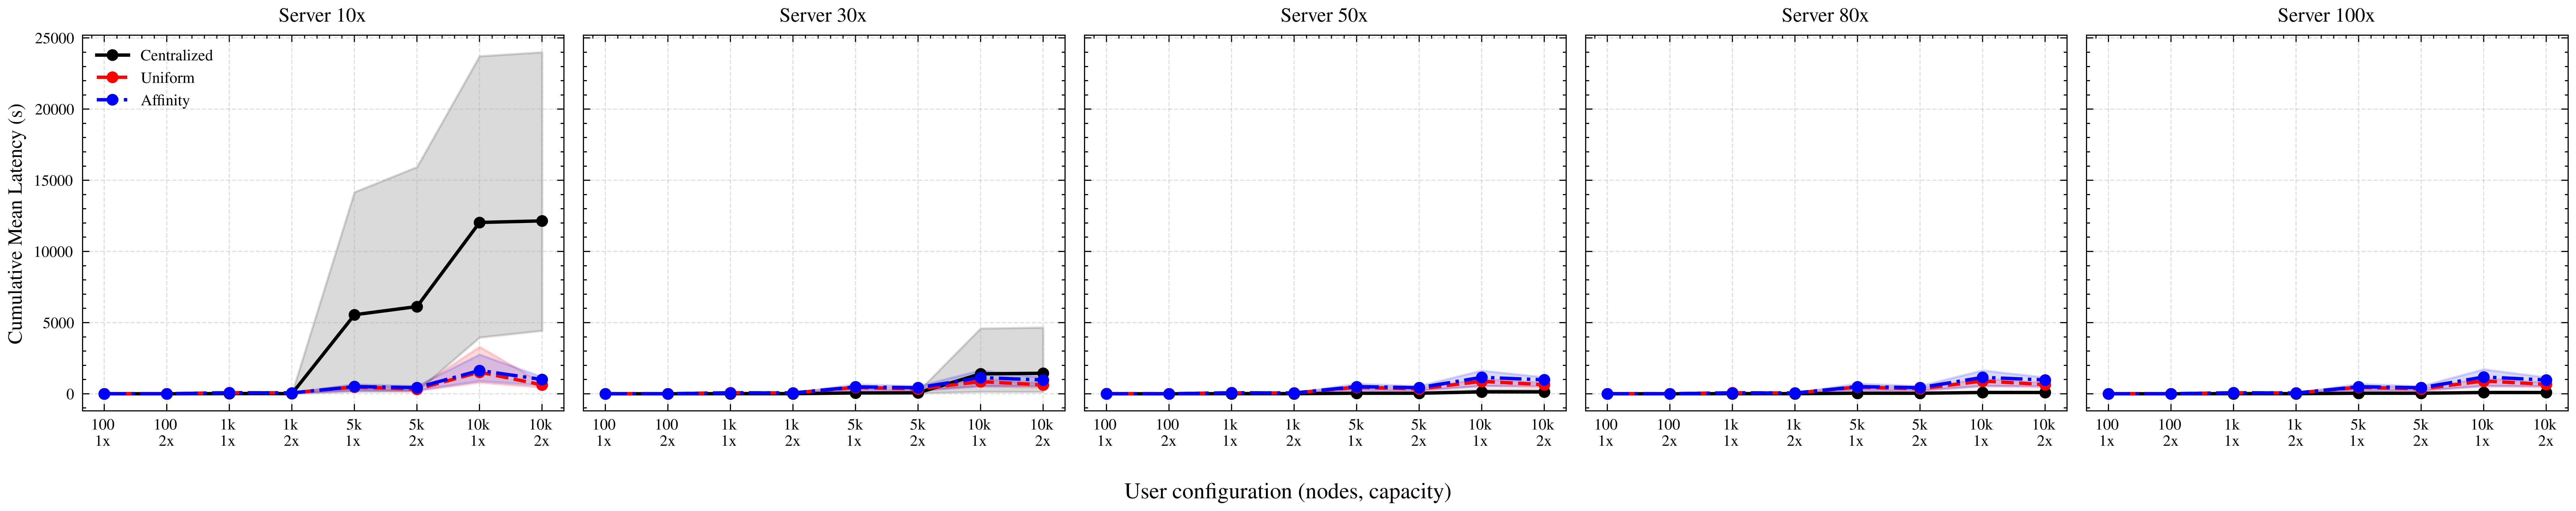

In [53]:
# Shared y-limits for cum_mean individual figures
_finite = [v for vals in _all_vals.values() for v in vals[2] if not np.isnan(v)]
_y_pad  = (max(_finite) - min(_finite)) * 0.05
_ylim_cum_mean = (min(_finite) - _y_pad, max(_finite) + _y_pad)

# Separate figures: cumulative mean latency, shaded bands across request types
for i, server_mult in enumerate(server_mults):
    fig, ax = plt.subplots(figsize=(4, 3))

    for policy, policy_label in zip(POLICIES, POLICY_LABELS):
        color = POLICY_COLORS[policy]
        ls    = POLICY_LINESTYLES[policy]

        task_cum_mean = np.array([_all_vals[(server_mult, t, policy)][2] for t in range(n_tasks)])
        mean_vals     = np.nanmean(task_cum_mean, axis=0)
        min_vals      = np.nanmin(task_cum_mean, axis=0)
        max_vals      = np.nanmax(task_cum_mean, axis=0)

        ax.plot(x_pos, mean_vals, color=color, linestyle=ls, marker="o",
                markersize=4, markeredgewidth=1.2, linewidth=1.5, label=policy_label)
        ax.fill_between(x_pos, min_vals, max_vals, color=color, alpha=0.15)

    ax.set_ylim(_ylim_cum_mean)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, fontsize=14)
    ax.tick_params(axis="y", labelsize=10)
    ax.tick_params(axis="x", which="minor", bottom=False)
    ax.set_xlabel("User configuration", fontsize=18)
    ax.grid(True, linestyle="--", alpha=0.4)

    if i == 0:
        ax.set_ylabel("Cumulative Mean Latency (s)", fontsize=18)
        ax.legend(fontsize=10.5, loc="upper left", ncol=1)

    fname = f"cum_mean_latency_server_{server_mult}x.pdf"
    plt.tight_layout()
    plt.savefig(os.path.join(figures_dir, fname), bbox_inches="tight")
    print(f"Figure {i + 1} — server {server_mult}x  →  {fname}")
    plt.show()

# 1×5 grid: cumulative mean latency
fig, axes = plt.subplots(
    1, len(server_mults),
    figsize=(3.2 * len(server_mults), 3.2),
    sharex=True,
    sharey=True
)

for col, server_mult in enumerate(server_mults):
    ax = axes[col]

    for policy, policy_label in zip(POLICIES, POLICY_LABELS):
        color = POLICY_COLORS[policy]
        ls    = POLICY_LINESTYLES[policy]

        task_cum_mean = np.array([_all_vals[(server_mult, t, policy)][2] for t in range(n_tasks)])
        mean_vals     = np.nanmean(task_cum_mean, axis=0)
        min_vals      = np.nanmin(task_cum_mean, axis=0)
        max_vals      = np.nanmax(task_cum_mean, axis=0)

        ax.plot(x_pos, mean_vals, color=color, linestyle=ls,
                marker="o", markersize=4, markeredgewidth=1.2,
                linewidth=1.5, label=policy_label)
        ax.fill_between(x_pos, min_vals, max_vals, color=color, alpha=0.15)

    ax.set_title(f"Server {server_mult}x", fontsize=9, fontweight="bold")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, fontsize=7)
    ax.tick_params(axis="y", labelsize=7)
    ax.tick_params(axis="x", which="minor", bottom=False)
    ax.grid(True, linestyle="--", alpha=0.4)

axes[0].set_ylabel("Cumulative Mean Latency (s)", fontsize=9)
axes[0].legend(fontsize=7, loc="upper left")

fig.supxlabel("User configuration (nodes, capacity)", fontsize=10, y=0.01)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "cum_mean_latency_grid.pdf"), bbox_inches="tight")
plt.show()